# Rescaled Fits — Predicted Conditions vs Observed Correlations

New NPE fits of conditions 01–04 (`*_rescaled`, trained 2026-11-17 on `nn_training_<cond>_rescaled.csv`) were
conditioned on the EA4 PGS correlations (`observed_correlations_PGS_ea4new.csv`) and the updated EA phenotypic
correlations (`observed_correlations_pheno_021126.csv`). Each condition was then simulated at the posterior means
(`Scripts/run_rc_paper/run_predicted_condition_rc_*.py`, 100 replicates, N = 40,000, compiled with
`compile_predicted_condition.py`), and this notebook compares the simulated relative correlations with the observed
ones.

**What differs from the previous run** (`Analysis_NPE_wider.ipynb`, same observed data, same design):
- **The engine.** The training data and the predicted conditions were simulated after the engine fix of 2026-11-08:
  `vg` is now the founder heritability (founder genetic variance `vg`, environmental variance 1 − `vg`, phenotypic
  variance 1), and the shared family environment `s_mat` is applied. The sampled ranges are unchanged (mostly
  0.05–0.95), so founder h² can now be 0.05–0.95 instead of 0.51–0.95.
- **Condition 03's fixed values.** `re` = 0.7 (was 0.1) and `s` = 0.3 on all four paths (was 0.5, which had no
  effect); `prop_h2_latent1` stays at 0.7. These were chosen from local simulations at a founder h² of 0.35
  (`run_rc_paper_wider/diagnose_02_03/`).
- **Training simulations.** A node failure lost 40 simulations of 02 and 320 of 03, which leaves 19,960 and 19,680;
  01 has 20,000 and 04 17,500 (`n_gen` 4–10, as before).
- Everything else is as in the wider run: the 52 features (26 relationship types, PGS and phenotypic), 15 generations
  for 01–03, and the NPE settings.

**Heritability in this notebook.** Every table reports the founder (base) heritability h². In this run that is `vg`
itself. The wider run's estimates come from the old engine, so they are converted with h² = 1/(2 − `vg`), as in
`Analysis_NPE_wider.ipynb`.

**Reading the figures.** For each relationship type, the bars are the simulated PGS correlations (blue) and
phenotypic correlations (teal; error bars: SD across the 100 replicates); the diamond on each bar is the
observed value. All 26 types are sorted by the observed PGS correlation.

**Fit criteria.** Simulated and observed correlations are compared on Fisher's z scale (z = arctanh r): *RMSE (z)*
is the root-mean-square difference and *bias (z)* the mean of simulated − observed. *Misfit* is the measure of
`run_rc_paper_wider/diagnose_02_03/diagnose_02_03.ipynb`: the root-mean-square over the 52 correlations of
(simulated − observed) / √(SE² + 0.01²). About 1 would mean agreement within sampling error. The tables below the
figures still split the 26 types into the 16 original and 10 added ones, but both runs fit all 26, so the split is
not an out-of-sample test.

**Results in short.**
- **Conditions 02 and 03 now fit best, and about equally well.** Their misfit falls to 1.95 and 1.96 (from 2.61
  and 8.42). Condition 03 changes most: its phenotypic RMSE (z) falls from 0.165 to 0.022, the lowest of any
  condition, but its PGS correlations are too high (22 of 26).
- **Only condition 02 puts EA's founder heritability in the 0.3–0.4 wanted:** 0.38 (95% interval 0.36–0.40). It is
  0.51 in 01, 0.59 in 04, and 0.08 in 03, at the lower end of its range.
- **Conditions 01 and 04 barely change** and are slightly worse (misfit 4.50 → 4.60 and 4.24 → 4.76 for 01's two
  traits, 2.51 → 2.71 for 04). 01 still cannot produce the in-law phenotypic correlations; 04 overshoots them.
- **The spousal–sibling trade-off of the old engine is gone.** The observed spouse and sibling correlations (0.43 and
  0.37) now lie inside the training simulations of every condition.
- **In the analysed generations, EA's heritability is above the founder value** (0.52 in 02, from 0.38), and the PGS
  predicts 10–27% of EA's variance (17% in 02); see the section on the final generations.
- **03's estimate is not settled.** Founder h² and `rg` sit at the ends of their ranges, and the best-fitting training
  simulations have h² 0.07–0.38 with lower `rg`.
- **No condition reproduces the data within sampling error.** The misfit is at least 1.95 everywhere, and the 52
  observed correlations together lie far outside the simulated distribution of every fit, so the estimates are
  extrapolations and their posterior intervals are too narrow.

Parameter meanings, the simulation model and the NPE are documented in the repository `README.md`.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from pathlib import Path

# ── Paths and observed data ────────────────────────────────────────────────
script_dir = Path(".")
pgs_table = pd.read_csv(script_dir / "observed_correlations_PGS_ea4new.csv").set_index("RelType")
pheno_table = pd.read_csv(script_dir / "observed_correlations_pheno_021126.csv").set_index("RelType")
obs_pgs, obs_pheno = pgs_table["Correlation"], pheno_table["Correlation"]

# the 16 relationship types of the first fits, and the 10 added with the EA4 data (both runs fit all 26)
old_types = pd.read_csv(script_dir / "observed_correlations_PGS.csv")["RelType"]
ORIGINAL_TYPES = [t for t in old_types if t in obs_pgs.index]
ADDED_TYPES = [t for t in obs_pgs.index if t not in set(old_types)]
ALL_TYPES = list(obs_pgs.index)

# this run (corrected engine) and the previous one (same design and observed data, old engine)
RUNS = {"rescaled": "rescaled, corrected engine (this run)", "wider": "wider, old engine"}


def run_dir(fit, run="rescaled"):
    return script_dir / f"results_npe_unweighted_{fit}_{run}"


def predictions_dir(fit, run="rescaled"):
    return run_dir(fit, run) / "predictions"


def pred_path(fit, run="rescaled"):
    """Predicted-condition summary file of a run."""
    return predictions_dir(fit, run) / f"summary_statistics_{fit}_{run}.csv"


# condition -> NPE fit(s) giving its parameters, fit filed with its summary, and compared trait(s);
# fit names are given without the run suffix
CONDITIONS = {
    "01DirAM": dict(title="Condition 01 — Direct AM", fits=["01DirAM_AE", "01DirAM_AFE"],
                    summary="01DirAM_AE", traits=[(1, "Trait 1 (AE)"), (2, "Trait 2 (AFE)")]),
    "02AElatentAM": dict(title="Condition 02 — AE latent AM", fits=["02AElatentAM"],
                         summary="02AElatentAM", traits=[(1, "Trait 1 (EA)")]),
    "03EnvLatentAM": dict(title="Condition 03 — Environmental latent AM", fits=["03EnvLatentAM"],
                          summary="03EnvLatentAM", traits=[(1, "Trait 1 (EA)")]),
    "04EAmigration": dict(title="Condition 04 — EA-driven migration", fits=["04EAmigration"],
                          summary="04EAmigration", traits=[(1, "Trait 1 (EA)")]),
}

MEANING = {
    "prop_h2_latent1": "share of trait-1 genetic variance not captured by the PGS",
    "prop_h2_latent2": "share of trait-2 genetic variance not captured by the PGS",
    "vg1": "founder (base) heritability of trait 1",
    "vg2": "founder (base) heritability of trait 2",
    "am11": "spousal correlation on trait 1",
    "am22": "spousal correlation on trait 2",
    "f11": "vertical transmission, trait 1",
    "f22": "vertical transmission, trait 2",
    "re": "environmental correlation between the traits",
    "rg": "genetic correlation between the traits",
    "move_p": "fraction of each sex per island migrating each generation",
    "n_gen": "generations since the random founders (categorical posterior)",
}

# colours as in the earlier notebooks: PGS blue, phenotypic teal, ACCENT for the estimate
BAR_COLORS = {"PGS": "#2a78d6", "Phenotypic": "#199e70"}
ACCENT = "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
TOL = 0.01    # correlation-scale tolerance added to the observed SE in the misfit

# Founder heritability in every table. In this run vg is the founder heritability. In the wider run
# (old engine) the genetic variance was about 1 whatever vg was, so its founder h² is 1/(2 − vg).
H2_LABEL = {"vg1": "h²1 (founder)", "vg2": "h²2 (founder)"}


def to_h2(p, value, run):
    """Founder heritability for vg parameters (converted for the old-engine wider run); other values as they are."""
    if p in H2_LABEL and run == "wider":
        return 1 / (2 - np.asarray(value, dtype=float))
    return value


def show(df, precision=4):
    display(df.style.hide(axis="index").format(precision=precision, na_rep="–"))


def simulated_range(fit, run):
    cfg = json.loads((run_dir(fit, run) / "config.json").read_text())
    bounds = dict(zip(cfg["prior_params"], zip(cfg["prior_lower"], cfg["prior_upper"])))
    if cfg.get("count_param"):
        bounds[cfg["count_param"]] = (min(cfg["count_values"]), max(cfg["count_values"]))
    return bounds


def parameter_table(key):
    """Posterior of every estimated parameter, with its simulated range and the wider run's value (founder h²)."""
    rows = []
    for fit in CONDITIONS[key]["fits"]:
        new = pd.read_csv(predictions_dir(fit) / "posterior_summary.csv").set_index("parameter")
        prev = pd.read_csv(predictions_dir(fit, "wider") / "posterior_summary.csv").set_index("parameter")
        bounds, prev_bounds = simulated_range(fit, "rescaled"), simulated_range(fit, "wider")
        sampling = json.loads((predictions_dir(fit) / "posterior_sampling.json").read_text())
        print(f"{fit}_rescaled: {sampling['share_of_unconstrained_flow_inside_prior']:.1%} of the unrestricted "
              f"posterior inside the simulated range -> {sampling['sampling_method']} sampling "
              f"({sampling['n_samples']:,} draws)")
        for p, r in new.iterrows():
            lo, hi = bounds[p]
            earlier = to_h2(p, prev.loc[p, "mean"], "wider") if p in prev.index else np.nan
            prev_lo, prev_hi = to_h2(p, np.array(prev_bounds[p]), "wider") if p in prev_bounds else (np.nan, np.nan)
            rows.append({"NPE fit": f"{fit}_rescaled", "parameter": H2_LABEL.get(p, p), "meaning": MEANING[p],
                         "estimate": r["mean"], "posterior SD": r["std"],
                         "95% interval": f"{r['ci_lower_2.5']:.3f} – {r['ci_upper_97.5']:.3f}",
                         "simulated range": f"{lo:.2f} – {hi:.2f}",
                         "position in range": f"{100 * (r['mean'] - lo) / (hi - lo):.0f}%",
                         "wider estimate": float(earlier),
                         "wider range": "fixed" if np.isnan(prev_lo) else f"{prev_lo:.2f} – {prev_hi:.2f}",
                         "change": r["mean"] - float(earlier)})
    show(pd.DataFrame(rows))


def load_summary(csv_path):
    """Predicted-condition summary_statistics CSV -> one row per relationship type."""
    df = pd.read_csv(csv_path)
    wide = df.pivot(index="RelationshipPath", columns="Variable",
                    values=["Correlation_Mean", "Correlation_SD"])
    wide.columns = [f"{v}_{c}" for v, c in wide.columns]
    return wide


def z_diff(pred, obs):
    """Simulated − observed correlations on Fisher's z scale (z = arctanh r)."""
    return np.arctanh(pred) - np.arctanh(obs)


def errors(pred, obs, types):
    """RMSE and bias of simulated against observed correlations over `types`, on Fisher's z scale."""
    p, o = pred.reindex(types), obs.reindex(types)
    ok = p.notna() & o.notna()
    diff = z_diff(p[ok], o[ok])
    return {"n": int(ok.sum()), "RMSE (z)": np.sqrt((diff ** 2).mean()), "bias (z)": diff.mean(),
            "too high": f"{int((diff > 0).sum())} of {int(ok.sum())}"}


def error_table(frame, trait):
    groups = [(f"{label}, {name}", var, obs, types)
              for label, var, obs in (("PGS", "PGS", obs_pgs), ("phenotypic", "Y", obs_pheno))
              for name, types in (("16 original types", ORIGINAL_TYPES), ("10 added types", ADDED_TYPES),
                                  ("all 26 types", ALL_TYPES))]
    return pd.DataFrame([{"correlations": label,
                          **errors(frame[f"Correlation_Mean_{var}{trait}"], obs, types)}
                         for label, var, obs, types in groups])


def misfit_of(frame, trait):
    """RMS over the 52 correlations of (simulated − observed) / sqrt(SE² + 0.01²), as in diagnose_02_03."""
    parts = [(frame[f"Correlation_Mean_{var}{trait}"].reindex(ALL_TYPES) - table["Correlation"].reindex(ALL_TYPES))
             / np.sqrt(table["SE"].reindex(ALL_TYPES) ** 2 + TOL ** 2)
             for var, table in (("PGS", pgs_table), ("Y", pheno_table))]
    return float(np.sqrt((pd.concat(parts) ** 2).mean()))


def error_box(ax, table, misfit):
    """Box in the top-right corner: RMSE (Fisher z) of the PGS and phenotypic correlations, and the misfit."""
    short = {"PGS, all 26 types": "PGS", "phenotypic, all 26 types": "pheno"}
    lines = [f"{'':<7}{'RMSE (z)':>9}"]
    for _, e in table[table["correlations"].isin(short)].iterrows():
        lines.append(f"{short[e['correlations']]:<7}{e['RMSE (z)']:>9.3f}")
    lines.append(f"{'misfit':<7}{misfit:>9.2f}")
    ax.text(0.995, 0.97, "\n".join(lines), transform=ax.transAxes, ha="right", va="top",
            family="monospace", fontsize=10,
            bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="0.6", alpha=0.95))


def plot_condition(key):
    """
    One figure per compared trait: simulated PGS and phenotypic correlations of each relationship type
    at the estimates, sorted by the observed PGS correlation, with the observed values as diamonds; the
    table below the figure gives the errors per group.
    """
    cond = CONDITIONS[key]
    frame = load_summary(pred_path(cond["summary"]))
    rel_types = sorted(obs_pgs.index, key=lambda r: -obs_pgs[r])
    x = np.arange(len(rel_types))
    width = 0.42
    sub = frame.reindex(rel_types)
    print(f"{cond['title']}: {pred_path(cond['summary'])} "
          f"({int(pd.read_csv(pred_path(cond['summary']))['N_Iterations'].max())} replicates)")

    for trait, trait_label in cond["traits"]:
        fig, ax = plt.subplots(figsize=(22, 7))
        panels = (("PGS", f"PGS{trait}", obs_pgs, -width / 2), ("Phenotypic", f"Y{trait}", obs_pheno, width / 2))
        for i, (kind, var, obs, off) in enumerate(panels):
            ax.bar(x + off, sub[f"Correlation_Mean_{var}"], width, yerr=sub[f"Correlation_SD_{var}"],
                   capsize=2, error_kw=dict(lw=0.8, ecolor=MUTED), color=BAR_COLORS[kind],
                   edgecolor="white", linewidth=1.5, label=f"{kind} correlation (simulated)")
            ax.scatter(x + off, obs.reindex(rel_types), marker="D", s=110, facecolor="white",
                       edgecolor=INK, linewidth=1.5, zorder=5, label="Observed value" if i == 0 else None)
        table = error_table(frame, trait)
        error_box(ax, table, misfit_of(frame, trait))
        ax.set_xlabel("Relationship type", fontsize=11)
        ax.set_ylabel("Correlation", fontsize=11)
        ax.set_xticks(x)
        ax.set_xticklabels(rel_types, rotation=45, ha="right")
        ax.set_xlim(-0.6, len(rel_types) - 0.4)
        ax.legend(loc="upper center", fontsize=10, ncol=3, frameon=True)
        ax.grid(axis="y", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        ax.axhline(0, color=MUTED, linewidth=0.8)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#c3c2b7")
        ax.tick_params(colors=MUTED)
        top = np.nanmax([ax.get_ylim()[1], *obs_pgs.reindex(rel_types), *obs_pheno.reindex(rel_types)])
        ax.set_ylim(top=top * 1.15)          # room for the legend and the error box
        ax.set_title(f"{cond['title']}, {trait_label}", loc="left", fontsize=12)
        plt.tight_layout()
        plt.show()
        print(f"\n{trait_label}: simulated vs observed")
        show(table)


def largest_misses(key, trait=1, n=6):
    """The correlations (PGS and phenotypic) furthest from the observed ones on Fisher's z scale."""
    frame = load_summary(pred_path(CONDITIONS[key]["summary"]))
    rows = []
    for kind, var, obs in (("PGS", "PGS", obs_pgs), ("phenotypic", "Y", obs_pheno)):
        sim = frame[f"Correlation_Mean_{var}{trait}"].reindex(ALL_TYPES)
        for t in ALL_TYPES:
            rows.append({"type": t, "correlation": kind, "observed": obs[t], "simulated": sim[t],
                         "simulated − observed (z)": float(z_diff(sim[t], obs[t]))})
    d = pd.DataFrame(rows)
    show(d.reindex(d["simulated − observed (z)"].abs().sort_values(ascending=False).index).head(n), precision=3)

## Overview

Errors of each predicted condition against the observed correlations over all 26 types, for this run and the wider
run. Both are measured against the same observed data.

In [2]:
rows = []
for key, cond in CONDITIONS.items():
    frames = {run: load_summary(pred_path(cond["summary"], run)) for run in RUNS}
    for trait, trait_label in cond["traits"]:
        for run, run_label in RUNS.items():
            e = error_table(frames[run], trait).set_index("correlations")
            rows.append({
                "condition": cond["title"], "trait": trait_label, "run": run_label,
                "PGS RMSE (z)": e.loc["PGS, all 26 types", "RMSE (z)"],
                "PGS bias (z)": e.loc["PGS, all 26 types", "bias (z)"],
                "pheno RMSE (z)": e.loc["phenotypic, all 26 types", "RMSE (z)"],
                "pheno bias (z)": e.loc["phenotypic, all 26 types", "bias (z)"],
                "misfit": misfit_of(frames[run], trait),
            })
show(pd.DataFrame(rows), precision=3)

condition,trait,run,PGS RMSE (z),PGS bias (z),pheno RMSE (z),pheno bias (z),misfit
Condition 01 — Direct AM,Trait 1 (AE),"rescaled, corrected engine (this run)",0.037,-0.030,0.072,-0.059,4.601
Condition 01 — Direct AM,Trait 1 (AE),"wider, old engine",0.037,-0.030,0.070,-0.056,4.500
Condition 01 — Direct AM,Trait 2 (AFE),"rescaled, corrected engine (this run)",0.038,-0.031,0.074,-0.065,4.762
Condition 01 — Direct AM,Trait 2 (AFE),"wider, old engine",0.034,-0.025,0.067,-0.050,4.235
Condition 02 — AE latent AM,Trait 1 (EA),"rescaled, corrected engine (this run)",0.021,0.004,0.038,0.014,1.950
Condition 02 — AE latent AM,Trait 1 (EA),"wider, old engine",0.029,0.019,0.053,0.033,2.609
Condition 03 — Environmental latent AM,Trait 1 (EA),"rescaled, corrected engine (this run)",0.039,0.027,0.022,-0.005,1.961
Condition 03 — Environmental latent AM,Trait 1 (EA),"wider, old engine",0.088,0.081,0.165,0.136,8.417
Condition 04 — EA-driven migration,Trait 1 (EA),"rescaled, corrected engine (this run)",0.024,0.009,0.049,0.032,2.711
Condition 04 — EA-driven migration,Trait 1 (EA),"wider, old engine",0.024,0.010,0.044,0.024,2.514


- **Condition 03:** RMSE 0.088 → 0.039 (PGS) and 0.165 → 0.022 (phenotypic); the phenotypic bias goes from 0.136 to
  −0.005, while the PGS bias stays positive (0.081 → 0.027).
- **Condition 02:** RMSE 0.029 → 0.021 (PGS) and 0.053 → 0.038 (phenotypic), with both biases close to 0 (0.004 and
  0.014). Its PGS RMSE is the lowest of any condition.
- **Condition 01** changes by 0.007 or less in every RMSE; trait 2 is slightly worse (misfit 4.24 → 4.76).
- **Condition 04:** PGS RMSE unchanged (0.024), phenotypic 0.044 → 0.049.

These are the correlations that separate the conditions (`_Y`: phenotypic; `_PGS`: polygenic score), for both runs:

In [3]:
KEY = [("S", "Y"), ("M", "Y"), ("MS", "Y"), ("PSC", "Y"), ("S", "PGS"), ("M", "PGS"), ("MS", "PGS"), ("PSC", "PGS")]
row = {"": "observed", "run": ""}
row.update({f"{r}_{v}": (obs_pgs if v == "PGS" else obs_pheno)[r] for r, v in KEY})
rows = [row]
for key, cond in CONDITIONS.items():
    for run in RUNS:
        frame = load_summary(pred_path(cond["summary"], run))
        for trait, trait_label in cond["traits"]:
            rows.append({"": f"{cond['title'][:12]}, {trait_label}", "run": run,
                         **{f"{r}_{v}": frame.loc[r, f"Correlation_Mean_{v}{trait}"] for r, v in KEY}})
show(pd.DataFrame(rows), precision=3)

,run,S_Y,M_Y,MS_Y,PSC_Y,S_PGS,M_PGS,MS_PGS,PSC_PGS
observed,,0.369,0.433,0.261,0.160,0.562,0.158,0.117,0.207
"Condition 01, Trait 1 (AE)",rescaled,0.356,0.431,0.153,0.137,0.558,0.118,0.073,0.179
"Condition 01, Trait 2 (AFE)",rescaled,0.351,0.433,0.152,0.115,0.551,0.100,0.071,0.177
"Condition 01, Trait 1 (AE)",wider,0.369,0.431,0.159,0.144,0.557,0.117,0.073,0.179
"Condition 01, Trait 2 (AFE)",wider,0.383,0.446,0.170,0.153,0.564,0.130,0.083,0.186
"Condition 02, Trait 1 (EA)",rescaled,0.365,0.428,0.242,0.202,0.568,0.142,0.111,0.211
"Condition 02, Trait 1 (EA)",wider,0.434,0.454,0.264,0.232,0.580,0.170,0.133,0.229
"Condition 03, Trait 1 (EA)",rescaled,0.377,0.434,0.248,0.136,0.596,0.199,0.153,0.246
"Condition 03, Trait 1 (EA)",wider,0.635,0.450,0.376,0.405,0.629,0.269,0.223,0.300
"Condition 04, Trait 1 (EA)",rescaled,0.348,0.449,0.247,0.171,0.522,0.165,0.116,0.180


- **01** matches siblings and spouses (0.356 and 0.431 for trait 1), but in-laws are far too low (`MS_Y` 0.153
  against 0.261), and so is the spouse PGS correlation (0.118 against 0.158). This is as in the wider run.
- **02** is now close on all four phenotypic correlations: siblings 0.365 against 0.369 (0.434 before), spouses
  0.428, in-laws 0.242 against 0.261. Cousins are still too high (0.202 against 0.160).
- **03** now matches the phenotypic correlations of siblings (0.377; 0.635 before), spouses (0.434), in-laws (0.248)
  and cousins (0.136 against 0.160; 0.405 before). Its PGS correlations are too high: spouses 0.199 against 0.158,
  in-laws 0.153 against 0.117, siblings 0.596 against 0.562.
- **04** is much as before: close on the phenotypic correlations, with the sibling PGS correlation low (0.522
  against 0.562).

## Condition 01 — Direct AM (trait 1 AE, trait 2 AFE)

Two independent traits (`rg = re = 0`), each with direct phenotypic assortative mating (bivariate AM matrix
without cross-trait terms). Trait 1 is an AE model; trait 2 is an AFE model with vertical transmission
(`f22`). Each trait is estimated by its own univariate NPE: trait 1 by `01DirAM_AE_rescaled`, trait 2 by
`01DirAM_AFE_rescaled`. Both traits are therefore compared with the same observed EA correlations.

| Fixed parameter | Meaning | Value |
|---|---|---|
| `f11`, `f12`, `f21` | vertical transmission | 0 |
| `s11`, `s12`, `s21`, `s22` | shared family environment | 0 |
| `am12`, `am21` | cross-trait assortative mating | 0 |
| `rg`, `re` | genetic and environmental correlation between the traits | 0 |
| **Simulation** | | |
| generations | generations simulated (generations analysed) | 15 (analysed 12–14) |
| iterations | simulation replicates | 100 |

**Estimated parameters** (posterior mean; *position in range*: 0% = lower, 100% = upper end of the simulated range;
*wider*: the previous run, with founder h² converted from its `vg`):

In [4]:
parameter_table("01DirAM")

01DirAM_AE_rescaled: 100.0% of the unrestricted posterior inside the simulated range -> rejection sampling (4,000 draws)
01DirAM_AFE_rescaled: 90.2% of the unrestricted posterior inside the simulated range -> rejection sampling (4,000 draws)


NPE fit,parameter,meaning,estimate,posterior SD,95% interval,simulated range,position in range,wider estimate,wider range,change
01DirAM_AE_rescaled,prop_h2_latent1,share of trait-1 genetic variance not captured by the PGS,0.5893,0.0399,0.519 – 0.661,0.05 – 0.95,60%,0.6093,0.05 – 0.95,-0.0200
01DirAM_AE_rescaled,h²1 (founder),founder (base) heritability of trait 1,0.5052,0.0146,0.479 – 0.535,0.05 – 0.95,51%,0.5196,0.51 – 0.95,-0.0144
01DirAM_AE_rescaled,am11,spousal correlation on trait 1,0.4319,0.0118,0.411 – 0.451,0.05 – 0.95,42%,0.4318,0.05 – 0.95,0.0001
01DirAM_AFE_rescaled,prop_h2_latent2,share of trait-2 genetic variance not captured by the PGS,0.1367,0.0850,0.054 – 0.358,0.05 – 0.95,10%,0.5933,0.05 – 0.95,-0.4566
01DirAM_AFE_rescaled,am22,spousal correlation on trait 2,0.4340,0.0093,0.415 – 0.451,0.05 – 0.95,43%,0.4474,0.05 – 0.95,-0.0134
01DirAM_AFE_rescaled,f22,"vertical transmission, trait 2",0.2423,0.0251,0.179 – 0.274,0.00 – 0.50,48%,0.0053,0.00 – 0.50,0.2370
01DirAM_AFE_rescaled,h²2 (founder),founder (base) heritability of trait 2,0.1448,0.0362,0.099 – 0.234,0.05 – 0.95,11%,0.5232,0.51 – 0.95,-0.3784


- **Trait 1 hardly moves.** Founder h² is 0.51 (0.52 before, when 0.51 was the floor) and is now well inside its
  range; `am11` stays at 0.43 and `prop_h2_latent1` goes from 0.61 to 0.59.
- **Trait 2 changes a lot.** Founder h² falls from 0.52 to 0.14 and `f22` rises from 0.005 to 0.24, so trait 2's
  family resemblance now comes mostly from vertical transmission. `prop_h2_latent2` falls from 0.59 to 0.14, near
  the lower end of its range, with a wide posterior (95% interval 0.05–0.36). 90.2% of the unrestricted posterior
  lies inside the simulated range.

Condition 01 — Direct AM: results_npe_unweighted_01DirAM_AE_rescaled/predictions/summary_statistics_01DirAM_AE_rescaled.csv (100 replicates)


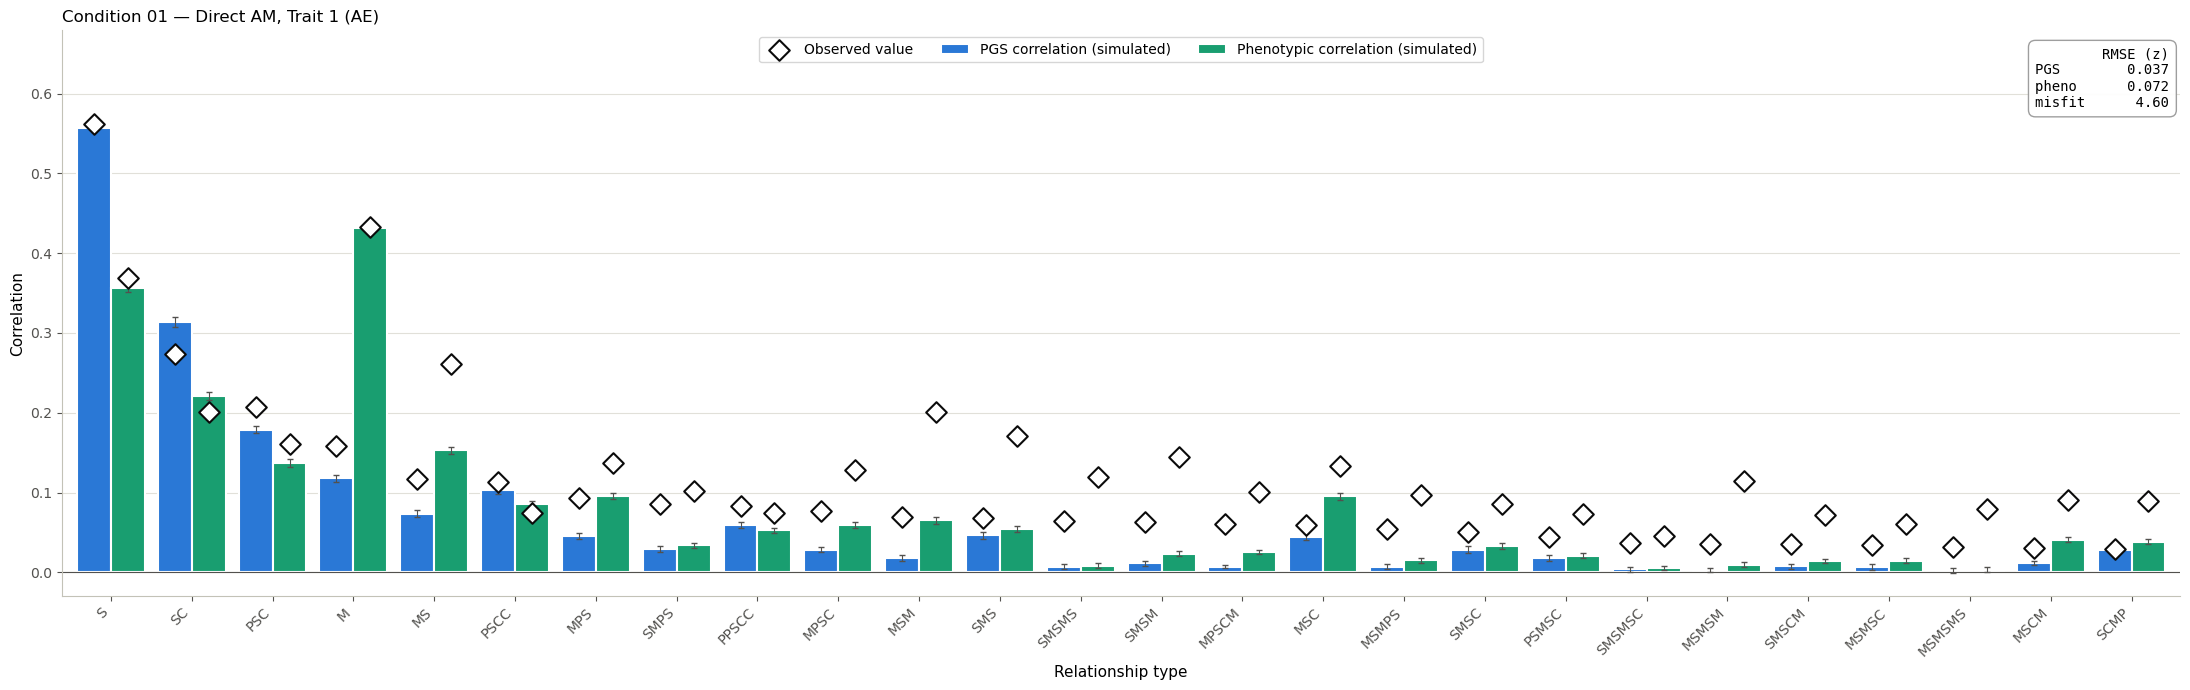


Trait 1 (AE): simulated vs observed


correlations,n,RMSE (z),bias (z),too high
"PGS, 16 original types",16,0.0348,-0.0321,0 of 16
"PGS, 10 added types",10,0.0403,-0.0270,1 of 10
"PGS, all 26 types",26,0.0370,-0.0301,1 of 26
"phenotypic, 16 original types",16,0.0799,-0.0673,0 of 16
"phenotypic, 10 added types",10,0.0572,-0.0465,2 of 10
"phenotypic, all 26 types",26,0.0720,-0.0593,2 of 26


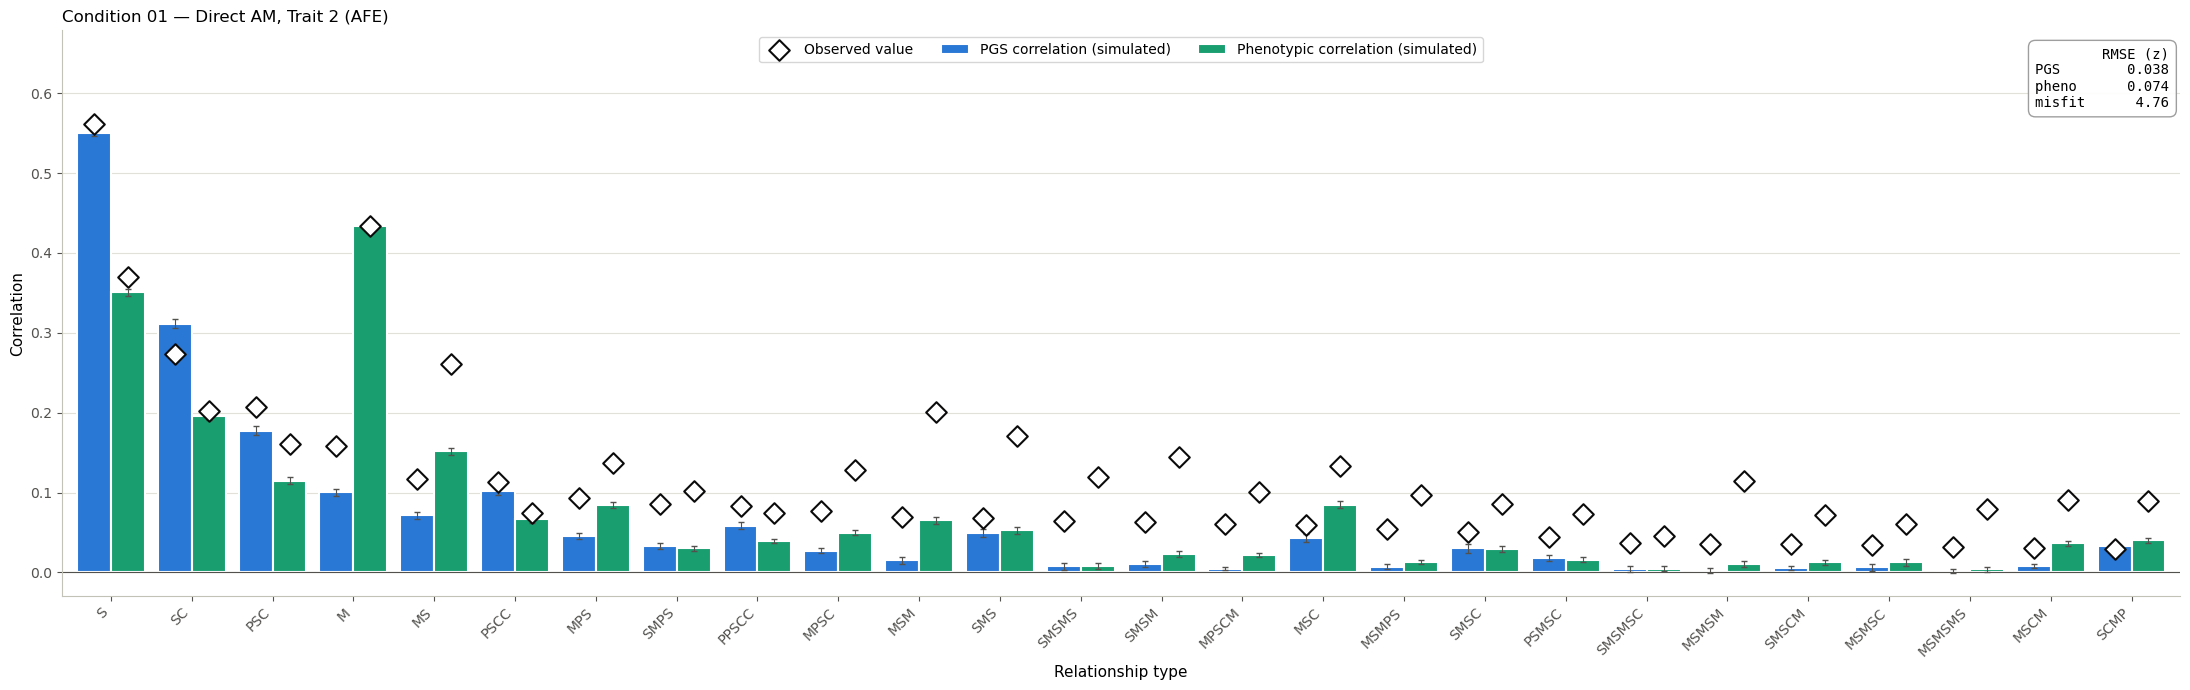


Trait 2 (AFE): simulated vs observed


correlations,n,RMSE (z),bias (z),too high
"PGS, 16 original types",16,0.0370,-0.0341,0 of 16
"PGS, 10 added types",10,0.0402,-0.0274,2 of 10
"PGS, all 26 types",26,0.0382,-0.0315,2 of 26
"phenotypic, 16 original types",16,0.0820,-0.0713,1 of 16
"phenotypic, 10 added types",10,0.0606,-0.0545,0 of 10
"phenotypic, all 26 types",26,0.0745,-0.0649,1 of 26


In [5]:
plot_condition("01DirAM")

In [6]:
largest_misses("01DirAM", trait=1)
largest_misses("01DirAM", trait=2)

type,correlation,observed,simulated,simulated − observed (z)
MSM,phenotypic,0.200,0.065,-0.138
SMSM,phenotypic,0.145,0.023,-0.122
SMS,phenotypic,0.171,0.054,-0.119
MS,phenotypic,0.261,0.153,-0.113
SMSMS,phenotypic,0.119,0.008,-0.112
MSMSM,phenotypic,0.115,0.010,-0.106


type,correlation,observed,simulated,simulated − observed (z)
MSM,phenotypic,0.200,0.065,-0.138
SMSM,phenotypic,0.145,0.023,-0.123
SMS,phenotypic,0.171,0.053,-0.120
MS,phenotypic,0.261,0.152,-0.114
SMSMS,phenotypic,0.119,0.008,-0.112
MSMSM,phenotypic,0.115,0.011,-0.105


The two traits give nearly the same correlations even though their parameters differ (an AE trait with h² 0.51,
against an AFE trait with h² 0.14 and `f22` = 0.24). The observed correlations do not separate the two models.

As in the wider run, almost every correlation is too low (1 of 26 PGS and 2 of 26 phenotypic correlations are too
high for trait 1), and the six largest misses are all in-law phenotypic correlations: `MSM` 0.065 against 0.200,
`SMSM` 0.023 against 0.145, `MS` 0.153 against 0.261. With direct AM alone, in-laws resemble each other only through
chains of spousal and sibling resemblance, and the corrected engine does not change that.

## Condition 02 — AE latent AM (trait 1 = EA)

Trait 1 is EA (AE model: a PGS part and a latent genetic part plus unique environment). Mating is phenotypic
assortative mating on trait 2, a fully latent factor (no PGS) that is genetically (`rg`) and environmentally
(`re`) correlated with EA. No vertical transmission, no shared family environment. NPE fit:
`02AElatentAM_rescaled`.

| Fixed parameter | Meaning | Value |
|---|---|---|
| `am11`, `am12`, `am21` | assortative mating (spousal correlations) | 0 |
| `f11`, `f22`, `f12`, `f21` | vertical transmission | 0 |
| `prop_h2_latent2` | share of trait-2 genetic variance not captured by a PGS | 1 |
| h²2 | founder heritability of trait 2 (`vg2`) | 0.5 |
| `s11`, `s12`, `s21`, `s22` | shared family environment | 0 |
| **Simulation** | | |
| generations | generations simulated (generations analysed) | 15 (analysed 12–14) |
| iterations | simulation replicates | 100 |

**Estimated parameters** (posterior mean; *position in range*: 0% = lower, 100% = upper end of the simulated range;
*wider*: the previous run, with founder h² converted from its `vg`):

In [7]:
parameter_table("02AElatentAM")

02AElatentAM_rescaled: 100.0% of the unrestricted posterior inside the simulated range -> rejection sampling (4,000 draws)

NPE fit,parameter,meaning,estimate,posterior SD,95% interval,simulated range,position in range,wider estimate,wider range,change
02AElatentAM_rescaled,prop_h2_latent1,share of trait-1 genetic variance not captured by the PGS,0.7821,0.0366,0.707 – 0.845,0.05 – 0.95,81%,0.6736,0.05 – 0.95,0.1084
02AElatentAM_rescaled,h²1 (founder),founder (base) heritability of trait 1,0.3812,0.0111,0.359 – 0.403,0.05 – 0.95,37%,0.5146,0.51 – 0.95,-0.1334
02AElatentAM_rescaled,re,environmental correlation between the traits,0.5001,0.0143,0.474 – 0.530,0.00 – 0.95,53%,0.8062,0.00 – 0.95,-0.3062
02AElatentAM_rescaled,am22,spousal correlation on trait 2,0.8489,0.0086,0.832 – 0.866,0.05 – 0.95,89%,0.7259,0.05 – 0.95,0.1230
02AElatentAM_rescaled,rg,genetic correlation between the traits,0.7558,0.0337,0.695 – 0.830,0.00 – 0.99,76%,0.6727,0.00 – 0.99,0.0830


- **Founder h² of EA falls from 0.51 (the old floor) to 0.38**, inside the 0.3–0.4 wanted, with a narrow posterior
  (0.36–0.40).
- **The other estimates move with it:** `re` falls from 0.81 to 0.50, `am22` rises from 0.73 to 0.85 (89% of its
  range), and `rg` rises from 0.67 to 0.76.
- **`prop_h2_latent1` is weakly identified** (0.78, from 0.67; test R² 0.62 on held-out simulations, against 0.86 or
  more for the other parameters).
- Essentially the whole unrestricted posterior lies inside the simulated range (99.99%, against 7.2% in the wider
  run).

Condition 02 — AE latent AM: results_npe_unweighted_02AElatentAM_rescaled/predictions/summary_statistics_02AElatentAM_rescaled.csv (100 replicates)


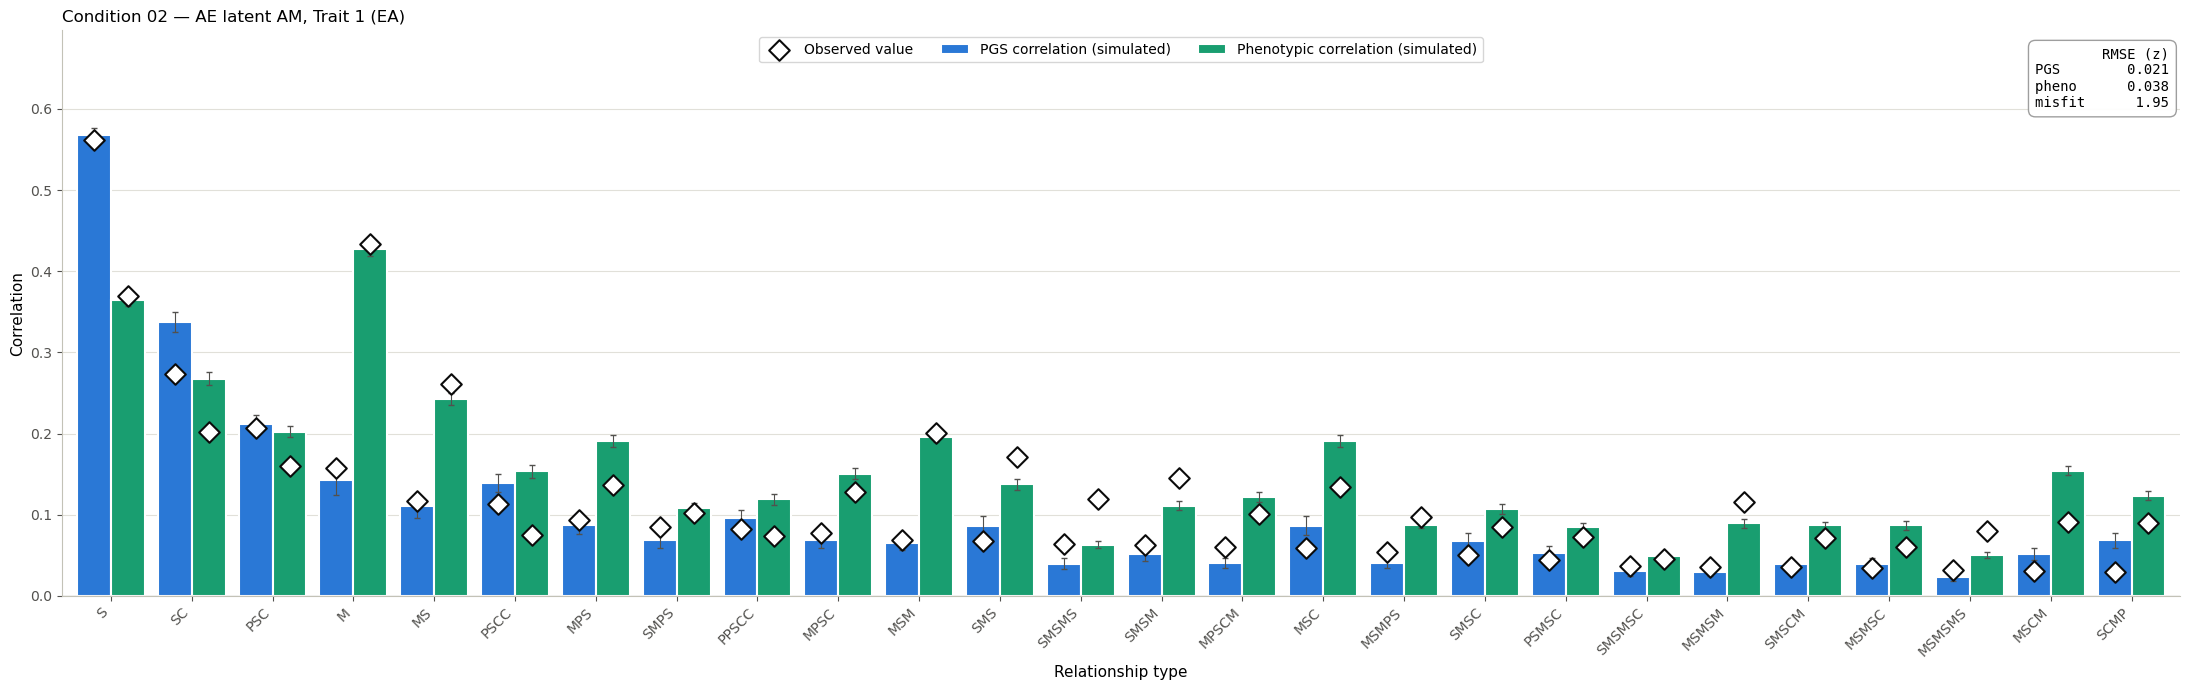


Trait 1 (EA): simulated vs observed


correlations,n,RMSE (z),bias (z),too high
"PGS, 16 original types",16,0.0136,0.0012,8 of 16
"PGS, 10 added types",10,0.0292,0.0094,5 of 10
"PGS, all 26 types",26,0.0210,0.0043,13 of 26
"phenotypic, 16 original types",16,0.0321,-0.0003,7 of 16
"phenotypic, 10 added types",10,0.0458,0.0361,9 of 10
"phenotypic, all 26 types",26,0.0380,0.0137,16 of 26


In [8]:
plot_condition("02AElatentAM")

In [9]:
largest_misses("02AElatentAM")

type,correlation,observed,simulated,simulated − observed (z)
PSCC,phenotypic,0.074,0.153,0.080
SC,PGS,0.274,0.337,0.070
SC,phenotypic,0.202,0.268,0.070
MSCM,phenotypic,0.091,0.154,0.064
MSC,phenotypic,0.134,0.191,0.059
SMSMS,phenotypic,0.119,0.063,-0.057


The fit is close throughout: about half the correlations are too high (13 of 26 PGS, 16 of 26 phenotypic). The
largest misses are relatives across generations, which come out too high: `PSCC` phenotypic 0.153 against 0.074,
`SC` 0.337 against 0.274 (PGS) and 0.268 against 0.202 (phenotypic), `MSCM` and `MSC` phenotypic about 0.06 too high.
The longest in-law chain, `SMSMS`, is too low (0.063 against 0.119). 9 of the 10 added types are too high on the
phenotypic scale.

## Condition 03 — Environmental latent AM (trait 1 = EA)

As condition 02 (mating on the fully latent trait 2, genetically correlated with EA), plus within-trait vertical
transmission on both traits (`f11`, `f22`) and a shared family environment. `s` = 0.3 on all four paths gives one
draw per sibship with variance 0.18 on each trait, perfectly correlated between the traits. The environmental
correlation is fixed at `re` = 0.7 and `prop_h2_latent1` at 0.7. NPE fit: `03EnvLatentAM_rescaled`.

| Fixed parameter | Meaning | Value |
|---|---|---|
| `prop_h2_latent1` | share of trait-1 genetic variance not captured by the PGS | 0.7 |
| `re` | environmental correlation between the traits | 0.7 (0.1 in the wider run) |
| `s11`, `s12`, `s21`, `s22` | shared family environment paths (Cov(S) = s sᵀ) | 0.3 (0.5, no effect, in the wider run) |
| `am11`, `am12`, `am21` | assortative mating (spousal correlations) | 0 |
| `prop_h2_latent2` | share of trait-2 genetic variance not captured by a PGS | 1 |
| h²2 | founder heritability of trait 2 (`vg2`) | 0.5 |
| `f12`, `f21` | cross-trait vertical transmission | 0 |
| **Simulation** | | |
| generations | generations simulated (generations analysed) | 15 (analysed 12–14) |
| iterations | simulation replicates | 100 |

**Estimated parameters** (posterior mean; *position in range*: 0% = lower, 100% = upper end of the simulated range;
*wider*: the previous run, with founder h² converted from its `vg`):

In [10]:
parameter_table("03EnvLatentAM")

03EnvLatentAM_rescaled: 6.7% of the unrestricted posterior inside the simulated range -> rejection sampling (4,000 draws)


NPE fit,parameter,meaning,estimate,posterior SD,95% interval,simulated range,position in range,wider estimate,wider range,change
03EnvLatentAM_rescaled,h²1 (founder),founder (base) heritability of trait 1,0.0777,0.0178,0.052 – 0.120,0.05 – 0.95,3%,0.5240,0.51 – 0.95,-0.4464
03EnvLatentAM_rescaled,f11,"vertical transmission, trait 1",0.1826,0.0183,0.141 – 0.210,0.00 – 0.40,46%,0.0919,0.00 – 0.40,0.0907
03EnvLatentAM_rescaled,f22,"vertical transmission, trait 2",0.0836,0.0097,0.065 – 0.103,0.00 – 0.40,21%,0.1122,0.00 – 0.40,-0.0286
03EnvLatentAM_rescaled,am22,spousal correlation on trait 2,0.7341,0.0115,0.711 – 0.756,0.05 – 0.95,76%,0.6941,0.05 – 0.95,0.0400
03EnvLatentAM_rescaled,rg,genetic correlation between the traits,0.9791,0.0104,0.952 – 0.990,0.00 – 0.99,99%,0.9169,0.00 – 0.99,0.0622


- **Two estimates sit at the ends of their ranges:** founder h² of EA at 0.08 (3% of its range; 0.52 before) and `rg`
  at 0.98 (99%; 0.92 before). Only 6.7% of the unrestricted posterior lies inside the simulated range (none in the
  wider run), so the estimate is pushed against both bounds.
- **Vertical transmission on EA doubles** (`f11` 0.09 → 0.18); `f22` (0.08) and `am22` (0.73) change little.
- **The fixed values do not suit this estimate.** `re` and `prop_h2_latent1` were chosen at a founder h² of 0.35;
  the fit lands at 0.08.

Condition 03 — Environmental latent AM: results_npe_unweighted_03EnvLatentAM_rescaled/predictions/summary_statistics_03EnvLatentAM_rescaled.csv (100 replicates)


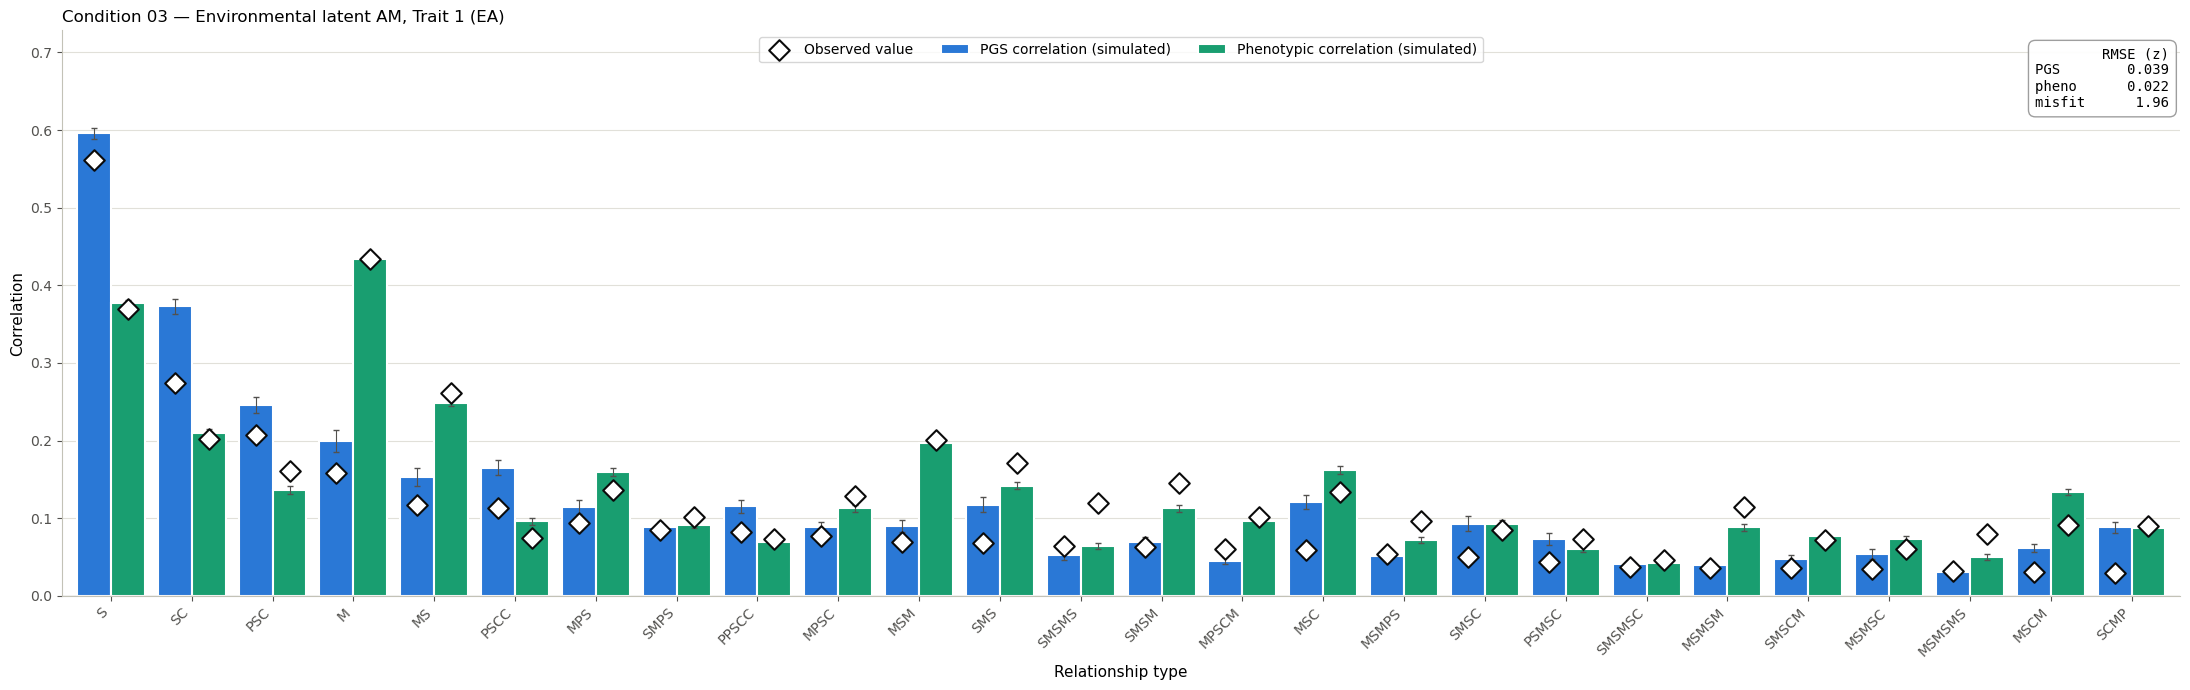


Trait 1 (EA): simulated vs observed


correlations,n,RMSE (z),bias (z),too high
"PGS, 16 original types",16,0.0340,0.0269,14 of 16
"PGS, 10 added types",10,0.0453,0.0283,8 of 10
"PGS, all 26 types",26,0.0387,0.0274,22 of 26
"phenotypic, 16 original types",16,0.0233,-0.0111,5 of 16
"phenotypic, 10 added types",10,0.0200,0.0044,5 of 10
"phenotypic, all 26 types",26,0.0221,-0.0052,10 of 26


In [11]:
plot_condition("03EnvLatentAM")

In [12]:
largest_misses("03EnvLatentAM")

type,correlation,observed,simulated,simulated − observed (z)
SC,PGS,0.274,0.373,0.111
MSC,PGS,0.059,0.121,0.062
SCMP,PGS,0.030,0.088,0.059
SMSMS,phenotypic,0.119,0.064,-0.056
PSCC,PGS,0.114,0.165,0.053
S,PGS,0.562,0.596,0.051


The phenotypic correlations now fit closely (RMSE 0.022; 10 of 26 too high), the largest change from the wider run,
where all 52 correlations were far too high. The remaining error is in the PGS correlations, 22 of 26 of which are
too high: `SC` 0.373 against 0.274, `MSC` 0.121 against 0.059, `SCMP` 0.088 against 0.030, `S` 0.596 against 0.562,
and the spouse PGS correlation 0.199 against 0.158. With mating on trait 2 and `rg` near 1, assortment on trait 2 is
almost assortment on EA's genetic value, which raises the PGS correlations of spouses and of their relatives.

## Condition 04 — EA-driven migration (trait 1 = EA)

EA is additive genetics (a PGS part and a latent part) plus unique environment: no assortative mating (random
mating within islands), no vertical transmission, no shared environment. There are 5 islands; each generation a
fraction `move_p` of each sex on each island migrates, and the movers are sorted on EA, so high-EA movers end up
on the high-numbered islands. The population starts from random founders and runs `n_gen` generations. Trait 2
is an inert dummy required by the bivariate engine. NPE fit: `04EAmigration_rescaled`.

| Fixed parameter | Meaning | Value |
|---|---|---|
| h²2 | dummy trait 2: founder heritability (`vg2`) | 0.5 |
| `prop_h2_latent2` | dummy trait 2: fully latent | 1 |
| `rg`, `re` | genetic and environmental correlation between the traits | 0 |
| `f11`, `f12`, `f21`, `f22` | vertical transmission | 0 |
| `am11`, `am12`, `am21`, `am22` | assortative mating (spousal correlations) | 0 |
| **Simulation** | | |
| generations | generations simulated (generations analysed) | `n_gen` = 4 (analysed 1–3) |
| iterations | simulation replicates | 100 |

**Estimated parameters** (posterior mean; *position in range*: 0% = lower, 100% = upper end of the simulated range;
*wider*: the previous run, with founder h² converted from its `vg`): `n_gen` is the posterior mode.

In [13]:
parameter_table("04EAmigration")

04EAmigration_rescaled: 100.0% of the unrestricted posterior inside the simulated range -> rejection sampling (4,000 draws)


NPE fit,parameter,meaning,estimate,posterior SD,95% interval,simulated range,position in range,wider estimate,wider range,change
04EAmigration_rescaled,move_p,fraction of each sex per island migrating each generation,0.4595,0.0071,0.448 – 0.472,0.01 – 0.95,48%,0.4507,0.01 – 0.95,0.0088
04EAmigration_rescaled,n_gen,generations since the random founders (categorical posterior),4.0000,0.0000,4.000 – 4.000,4.00 – 10.00,0%,4.0000,4.00 – 10.00,0.0000
04EAmigration_rescaled,h²1 (founder),founder (base) heritability of trait 1,0.5924,0.0084,0.576 – 0.609,0.05 – 0.95,60%,0.5822,0.51 – 0.95,0.0102
04EAmigration_rescaled,prop_h2_latent1,share of trait-1 genetic variance not captured by the PGS,0.6598,0.0177,0.626 – 0.693,0.05 – 0.95,68%,0.6346,0.05 – 0.95,0.0252


The estimates are close to the wider run's (`move_p` 0.451 → 0.460, founder h² 0.58 → 0.59, `prop_h2_latent1`
0.63 → 0.66), and the whole posterior lies inside the simulated range. This condition's founder h² was already above
the old engine's floor, so the fix changes little here. `n_gen` = 4 is again the lowest value the fit allows, because
`PSCC` and `PPSCC` do not exist at `n_gen` = 3.

Condition 04 — EA-driven migration: results_npe_unweighted_04EAmigration_rescaled/predictions/summary_statistics_04EAmigration_rescaled.csv (100 replicates)


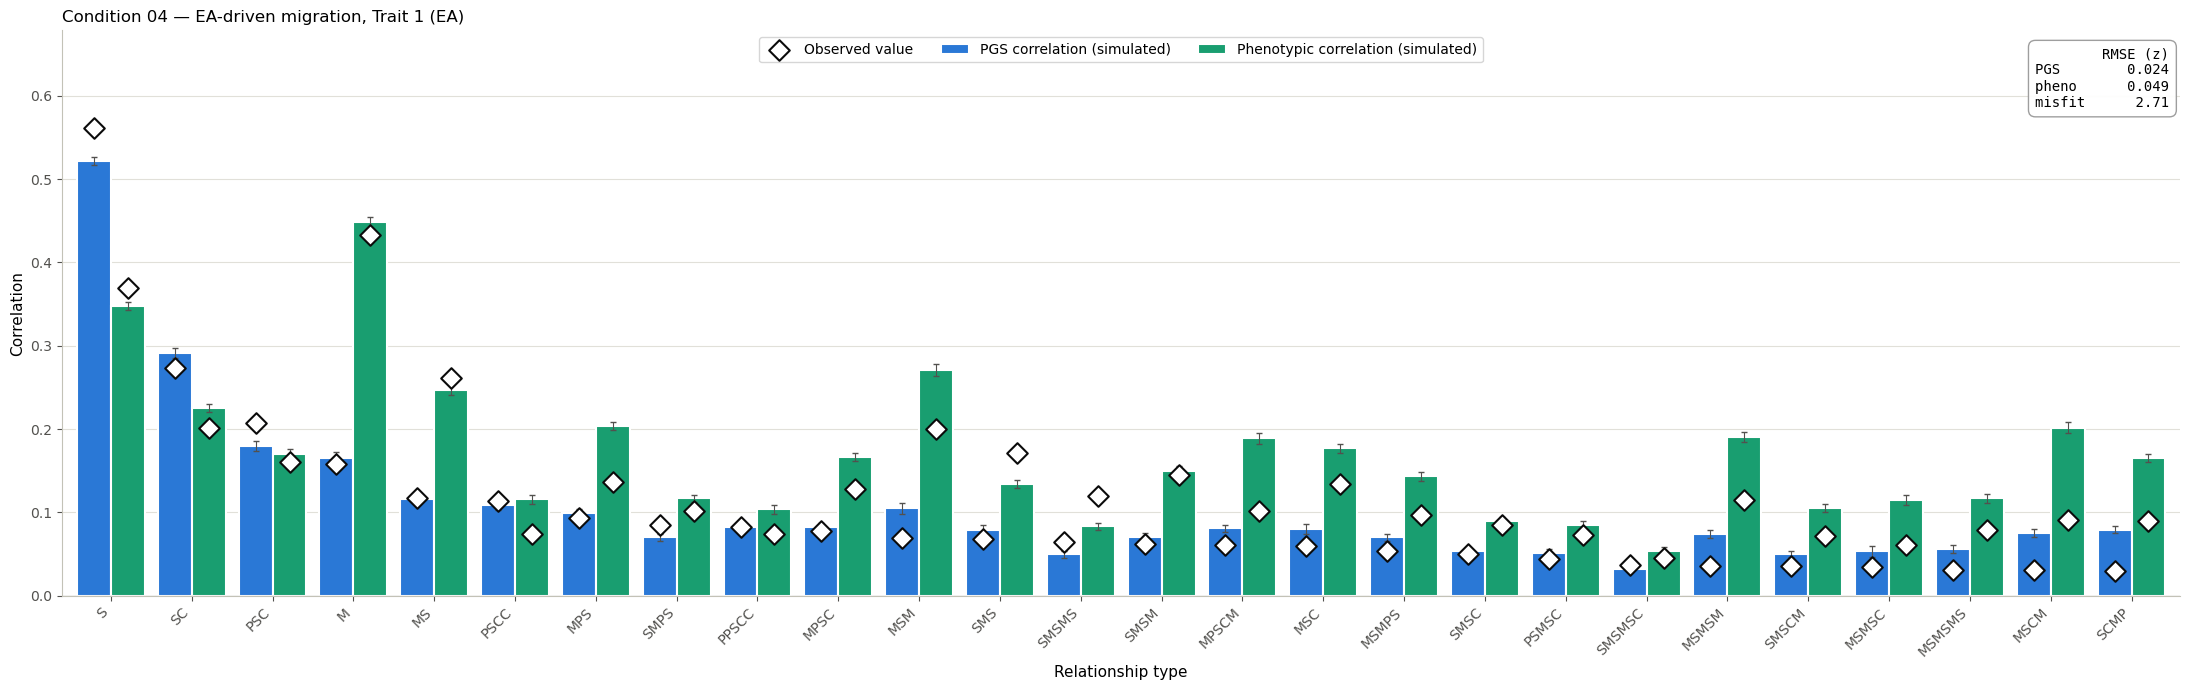


Trait 1 (EA): simulated vs observed


correlations,n,RMSE (z),bias (z),too high
"PGS, 16 original types",16,0.0234,0.0045,10 of 16
"PGS, 10 added types",10,0.0246,0.0156,8 of 10
"PGS, all 26 types",26,0.0239,0.0087,18 of 26
"phenotypic, 16 original types",16,0.0381,0.0167,12 of 16
"phenotypic, 10 added types",10,0.0626,0.0552,10 of 10
"phenotypic, all 26 types",26,0.0490,0.0315,22 of 26


In [14]:
plot_condition("04EAmigration")

In [15]:
largest_misses("04EAmigration")

type,correlation,observed,simulated,simulated − observed (z)
MSCM,phenotypic,0.091,0.202,0.114
MPSCM,phenotypic,0.101,0.189,0.090
MSMSM,phenotypic,0.115,0.190,0.077
SCMP,phenotypic,0.089,0.165,0.077
MSM,phenotypic,0.200,0.271,0.075
MPS,phenotypic,0.137,0.204,0.069


The PGS correlations fit as well as before (RMSE 0.024). The phenotypic correlations are too high in 22 of 26 types,
including all 10 added ones, and the largest misses are all in-laws: `MSCM` 0.202 against 0.091, `MPSCM` 0.189
against 0.101, `MSMSM` 0.190 against 0.115, `SCMP` 0.165 against 0.089, `MSM` 0.271 against 0.200. Sorting on EA
across islands makes in-laws too alike.

## The fits against their training simulations

The table uses the training data of each rescaled fit (`nn_training_*_rescaled.csv` and the row filters of
`run_npe_pipeline.py`) and its 52 features. It compares each condition's observed data with its training
simulations, with the simulation at this run's estimate, and with the best-fitting training simulation. *Mahalanobis*
is the distance of the 52 observed correlations from the training simulations (with their means and covariance),
and *training max* the largest such distance among the training simulations themselves. A training simulation is a
single replicate, so the best of 20,000 is slightly favoured by noise; the predicted condition averages 100
replicates.

In [16]:
# training data of each rescaled fit, as in run_npe_pipeline.py (RUNS): file and row filter
TRAINING = {"01DirAM_AE": ("01DirAM_rescaled", None), "01DirAM_AFE": ("01DirAM_rescaled", None),
            "02AElatentAM": ("02AElatentAM_rescaled", None), "03EnvLatentAM": ("03EnvLatentAM_rescaled", None),
            "04EAmigration": ("04EAmigration_rescaled", "param_n_gen >= 4")}
SUMMARY_OF = {"01DirAM_AE": "01DirAM_AE", "01DirAM_AFE": "01DirAM_AE", "02AElatentAM": "02AElatentAM",
              "03EnvLatentAM": "03EnvLatentAM", "04EAmigration": "04EAmigration"}
_training_files = {}


def features(fit):
    return (script_dir / "run_specs" / f"{fit}_rescaled" / "features.txt").read_text().split()


def fit_params(fit):
    return (script_dir / "run_specs" / f"{fit}_rescaled" / "params.txt").read_text().split()


def training_data(fit):
    """Training simulations of a rescaled fit with all its features present."""
    data, row_filter = TRAINING[fit]
    if data not in _training_files:
        _training_files[data] = pd.read_csv(script_dir / f"nn_training_{data}.csv")
    d = _training_files[data]
    return (d.query(row_filter) if row_filter else d).dropna(subset=features(fit))


def observed(feats):
    """Observed values of NPE features such as S_PGS1 or M_Y2."""
    return pd.Series({f: (obs_pgs if "_PGS" in f else obs_pheno)[f.rsplit("_", 1)[0]] for f in feats})


def observed_se(feats):
    return pd.Series({f: (pgs_table if "_PGS" in f else pheno_table).loc[f.rsplit("_", 1)[0], "SE"] for f in feats})


def simulated(fit, feats):
    """Mean over replicates of the predicted condition at this run's estimate, for an NPE fit's features."""
    s = pd.read_csv(pred_path(SUMMARY_OF[fit]))
    return pd.Series({f"{r.RelationshipPath}_{r.Variable}": r.Correlation_Mean for r in s.itertuples()})[feats]


def misfit_row(values, obs, se):
    return np.sqrt((((values - obs) / np.sqrt(se ** 2 + TOL ** 2)) ** 2).mean(axis=1 if values.ndim == 2 else 0))


rows = []
for fit in TRAINING:
    feats = features(fit)
    d, obs, se = training_data(fit), observed(feats), observed_se(feats)
    X = d[feats]
    mean, prec = X.mean().to_numpy(), np.linalg.pinv(np.cov(X.to_numpy(), rowvar=False))

    def mahalanobis(v):
        z = np.atleast_2d(v - mean)
        return np.sqrt(np.einsum("ij,jk,ik->i", z, prec, z))

    rmse = np.sqrt((z_diff(X, obs) ** 2).mean(axis=1))
    est = simulated(fit, feats)
    est_rmse = np.sqrt((z_diff(est, obs) ** 2).mean())
    outside = [f"{f} ({obs[f]:.3f}; simulated {X[f].min():.3f}–{X[f].max():.3f})"
               for f in feats if not X[f].min() <= obs[f] <= X[f].max()]
    rows.append({"NPE fit": f"{fit}_rescaled", "training simulations": len(d), "features": len(feats),
                 "Mahalanobis: observed": mahalanobis(obs.to_numpy())[0],
                 "Mahalanobis: training max": mahalanobis(X.to_numpy()).max(),
                 "observed outside the simulated range": "; ".join(outside) or "–",
                 "RMSE (z): best training simulation": rmse.min(),
                 "RMSE (z): at the estimate": est_rmse,
                 "simulations fitting better than the estimate": f"{(rmse < est_rmse).sum():,} ({(rmse < est_rmse).mean():.1%})",
                 "misfit: best training simulation": misfit_row(X, obs, se).min(),
                 "misfit: at the estimate": misfit_row(est, obs, se)})
show(pd.DataFrame(rows), precision=3)

NPE fit,training simulations,features,Mahalanobis: observed,Mahalanobis: training max,observed outside the simulated range,RMSE (z): best training simulation,RMSE (z): at the estimate,simulations fitting better than the estimate,misfit: best training simulation,misfit: at the estimate
01DirAM_AE_rescaled,20000,52,51.049,18.928,–,0.045,0.057,766 (3.8%),3.242,4.601
01DirAM_AFE_rescaled,20000,52,40.767,34.436,–,0.045,0.059,606 (3.0%),3.299,4.762
02AElatentAM_rescaled,19960,52,57.058,16.971,–,0.029,0.031,2 (0.0%),1.975,1.950
03EnvLatentAM_rescaled,19680,52,42.325,18.242,–,0.023,0.032,78 (0.4%),1.555,1.961
04EAmigration_rescaled,17500,52,39.407,13.365,–,0.032,0.039,47 (0.3%),2.311,2.711


- **Each observed correlation lies inside its simulated range, but the 52 together do not look like any
  simulation.** The observed Mahalanobis distance is 39–57, against at most 13–19 among the training simulations
  (34 for 01's trait 2, against 41 observed). The models reproduce each correlation, but not their pattern, so the
  posterior intervals are too narrow.
- **In 02 the estimate is about the best the training data offer:** 2 of 19,960 training simulations fit better on
  RMSE (z), and the misfit at the estimate (1.95) is below that of the best single training simulation (1.98).
- **In 03, 78 training simulations (0.4%) fit better** than the estimate, and the best has a misfit of 1.56,
  against 1.96 at the estimate. 03 has the best-fitting single simulation of all conditions.
- **In 01 and 04 the estimate is close to the best available** (3.8%, 3.0% and 0.3% fit better), but even the best
  training simulation has a misfit of 3.24–3.30 (01) and 2.31 (04).

### The spousal–sibling trade-off

Every training simulation of each condition by its spousal (`M_Y1`) and sibling (`S_Y1`) phenotypic EA correlation,
with the observed values, the simulation at this run's estimate and the best-fitting training simulation. In the
wider run, no simulation of 02 or 03 had the observed spouse and sibling correlations together.

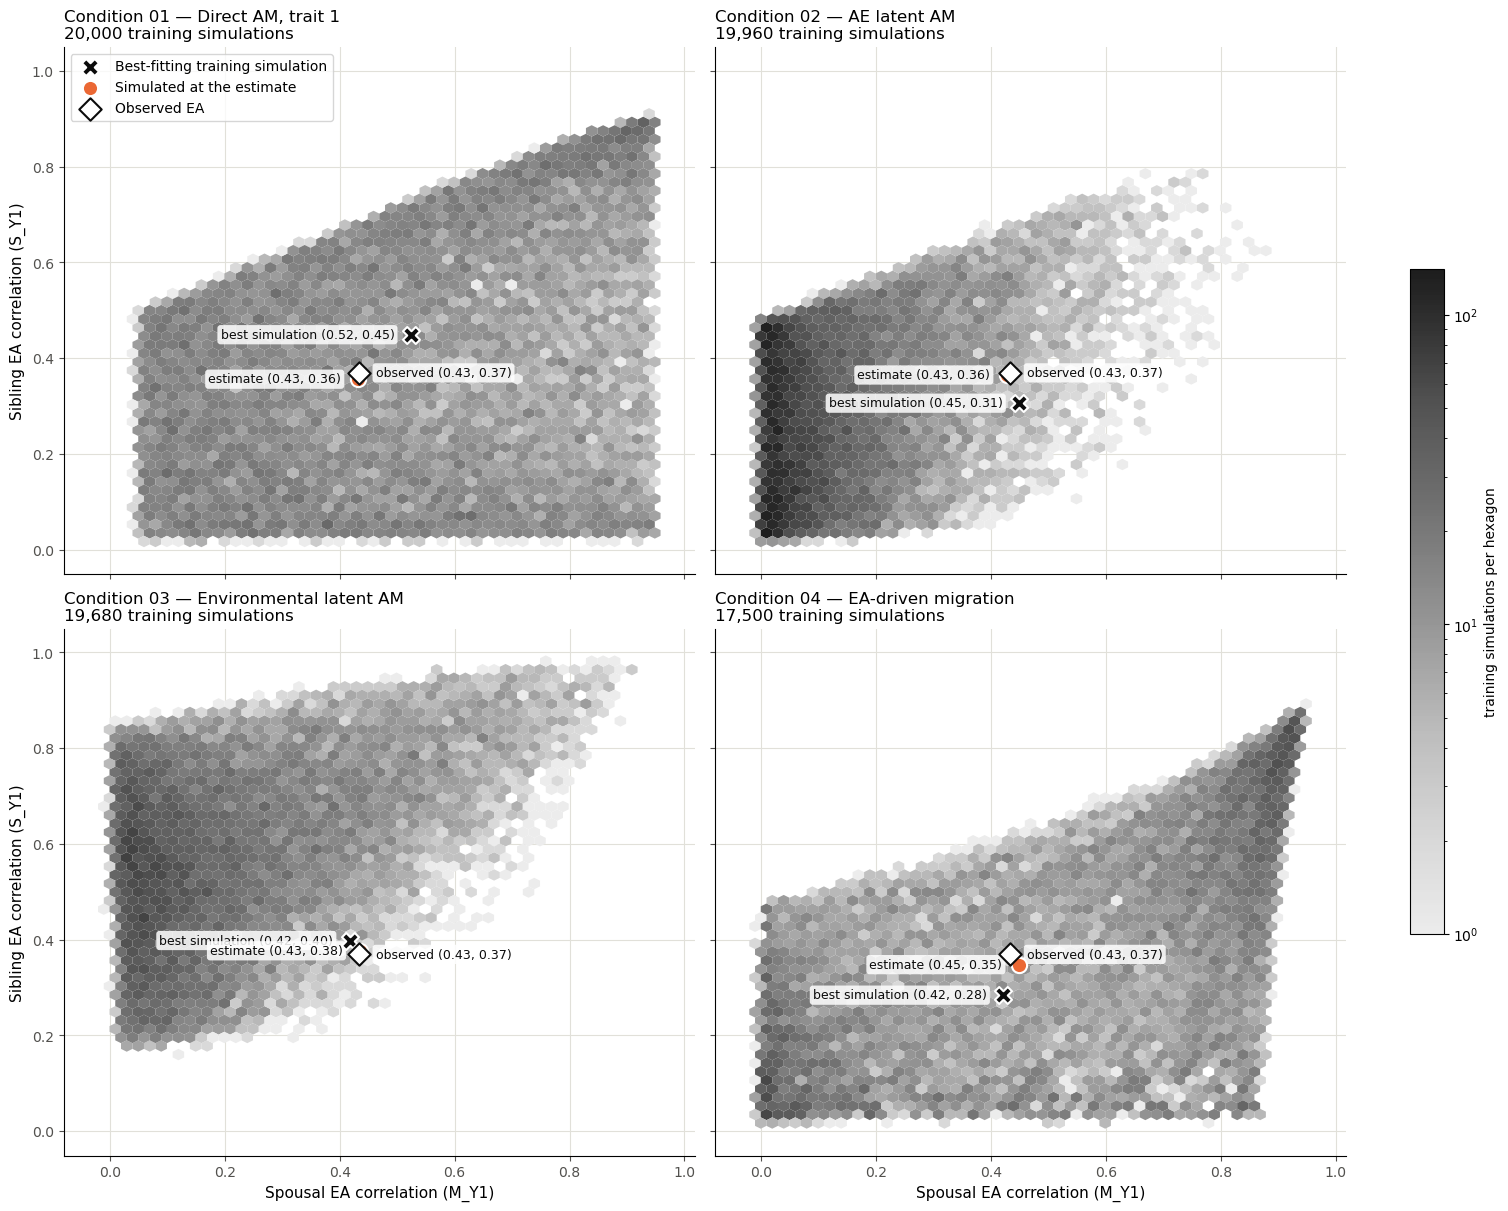

01DirAM_AE_rescaled: 1,297 of 20,000 simulations have M_Y1 within 0.03 of the observed 0.433; their S_Y1 is 0.025–0.697 (median 0.353; observed 0.369).
02AElatentAM_rescaled: 613 of 19,960 simulations have M_Y1 within 0.03 of the observed 0.433; their S_Y1 is 0.073–0.684 (median 0.455; observed 0.369).
03EnvLatentAM_rescaled: 931 of 19,680 simulations have M_Y1 within 0.03 of the observed 0.433; their S_Y1 is 0.270–0.935 (median 0.670; observed 0.369).
04EAmigration_rescaled: 785 of 17,500 simulations have M_Y1 within 0.03 of the observed 0.433; their S_Y1 is 0.029–0.620 (median 0.294; observed 0.369).


In [17]:
# grey ramp from light grey (one simulation) to near-black, so sparse hexagons stay visible
DENSITY = LinearSegmentedColormap.from_list("density", plt.cm.Greys(np.linspace(0.15, 0.9, 256)))
SHORT_LABEL = {"Best-fitting training simulation": "best simulation", "Simulated at the estimate": "estimate",
               "Observed EA": "observed"}
TITLES = {fit: CONDITIONS[key]["title"] + (", trait 1" if key == "01DirAM" else "")
          for fit, key in (("01DirAM_AE", "01DirAM"), ("02AElatentAM", "02AElatentAM"),
                           ("03EnvLatentAM", "03EnvLatentAM"), ("04EAmigration", "04EAmigration"))}
clouds = pd.concat([training_data(fit)[["M_Y1", "S_Y1"]] for fit in TITLES])
extent = (clouds["M_Y1"].min() - 0.02, clouds["M_Y1"].max() + 0.02, clouds["S_Y1"].min() - 0.02, clouds["S_Y1"].max() + 0.02)

fig, axes = plt.subplots(2, 2, figsize=(15, 12), sharex=True, sharey=True, layout="constrained")
hexbins = []
for ax, fit in zip(axes.flat, TITLES):
    feats = features(fit)
    d, obs = training_data(fit), observed(feats)
    best = d.loc[(z_diff(d[feats], obs) ** 2).mean(axis=1).idxmin()]
    est = simulated(fit, feats)
    hexbins.append(ax.hexbin(d["M_Y1"], d["S_Y1"], gridsize=50, cmap=DENSITY, mincnt=1, linewidths=0, extent=extent))
    points = (("Best-fitting training simulation", best, dict(marker="X", s=150, color=INK), "right"),
              ("Simulated at the estimate", est, dict(marker="o", s=120, color=ACCENT), "right"),
              ("Observed EA", obs, dict(marker="D", s=130, facecolor="white", edgecolor=INK), "left"))
    for label, p, style, align in points:     # labels left of the point, except the observed one
        style = {"edgecolor": "white", **style}
        ax.scatter(p["M_Y1"], p["S_Y1"], linewidth=1.5, zorder=5, label=label, **style)
        ax.annotate(f"{SHORT_LABEL[label]} ({p['M_Y1']:.2f}, {p['S_Y1']:.2f})", (p["M_Y1"], p["S_Y1"]),
                    xytext=(-12 if align == "right" else 12, 0), textcoords="offset points", ha=align, va="center",
                    fontsize=9, color=INK,
                    bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="none", alpha=0.85))
    ax.set_title(f"{TITLES[fit]}\n{len(d):,} training simulations", loc="left", fontsize=12)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED)
for ax in axes[1]:
    ax.set_xlabel("Spousal EA correlation (M_Y1)", fontsize=11)
for ax in axes[:, 0]:
    ax.set_ylabel("Sibling EA correlation (S_Y1)", fontsize=11)
axes[0, 0].legend(loc="upper left", fontsize=10, frameon=True)
norm = LogNorm(vmin=1, vmax=max(h.get_array().max() for h in hexbins))
for h in hexbins:
    h.set_norm(norm)
fig.colorbar(hexbins[-1], ax=axes, label="training simulations per hexagon", shrink=0.6)
plt.show()

for fit in TITLES:
    d = training_data(fit)
    near = d[(d["M_Y1"] - obs_pheno["M"]).abs() <= 0.03]
    print(f"{fit}_rescaled: {len(near):,} of {len(d):,} simulations have M_Y1 within 0.03 of the observed "
          f"{obs_pheno['M']:.3f}; their S_Y1 is {near['S_Y1'].min():.3f}–{near['S_Y1'].max():.3f} "
          f"(median {near['S_Y1'].median():.3f}; observed {obs_pheno['S']:.3f}).")

The observed point (spouses 0.43, siblings 0.37) now lies inside the cloud of every condition. Among the simulations
whose spousal correlation is within 0.03 of the observed one, the sibling correlation ranges from 0.07 to 0.68 in 02
and from 0.27 to 0.94 in 03, so it is no longer forced up with the spousal correlation. In the wider run every
simulation with a spousal correlation of 0.40 or more had a sibling correlation of at least 0.39 in 02 and 0.52 in 03.
In 03 the observed point is still at the lower edge of the cloud (median sibling correlation 0.67 at the observed
spousal correlation).

The estimates of all four conditions land within about 0.02 of the observed point.

### This run's estimate against the best training simulations

In [18]:
def best_simulations(fit):
    """This run's estimate against the five training simulations closest to the observed correlations."""
    feats, params = features(fit), fit_params(fit)
    t = 2 if fit.endswith("AFE") else 1          # condition 01's AFE fit uses the trait-2 correlations
    shown = [f"S_Y{t}", f"PSC_Y{t}", f"M_Y{t}", f"MS_Y{t}", f"S_PGS{t}", f"M_PGS{t}"]
    d, obs = training_data(fit), observed(feats)
    pgs_f, ph_f = [f for f in feats if "_PGS" in f], [f for f in feats if "_Y" in f]

    def fit_summary(values):
        z2 = z_diff(values[feats].astype(float), obs) ** 2
        return {"RMSE (z)": np.sqrt(z2.mean()), "PGS RMSE (z)": np.sqrt(z2[pgs_f].mean()),
                "pheno RMSE (z)": np.sqrt(z2[ph_f].mean()), **values[shown].astype(float)}

    estimate = pd.read_csv(predictions_dir(fit) / "posterior_summary.csv").set_index("parameter")["mean"]
    rmse = np.sqrt((z_diff(d[feats], obs) ** 2).mean(axis=1))
    rows = [{"": "observed", **obs[shown]},
            {"": "simulated at the estimate (100 replicates)", **{H2_LABEL.get(p, p): estimate[p] for p in params},
             **fit_summary(simulated(fit, feats))}]
    for i in rmse.nsmallest(5).index:
        rows.append({"": f"training simulation {d.loc[i, 'Condition']}",
                     **{H2_LABEL.get(p, p): d.loc[i, f"param_{p}"] for p in params}, **fit_summary(d.loc[i])})
    print(f"{fit}_rescaled")
    columns = ["", *[H2_LABEL.get(p, p) for p in params], "RMSE (z)", "PGS RMSE (z)", "pheno RMSE (z)", *shown]
    show(pd.DataFrame(rows)[columns], precision=3)


for fit in TRAINING:
    best_simulations(fit)

01DirAM_AE_rescaled


,prop_h2_latent1,h²1 (founder),am11,RMSE (z),PGS RMSE (z),pheno RMSE (z),S_Y1,PSC_Y1,M_Y1,MS_Y1,S_PGS1,M_PGS1
observed,–,–,–,–,–,–,0.369,0.160,0.433,0.261,0.562,0.158
simulated at the estimate (100 replicates),0.589,0.505,0.432,0.057,0.037,0.072,0.356,0.137,0.431,0.153,0.558,0.118
training simulation Condition_06466,0.573,0.565,0.523,0.045,0.028,0.057,0.449,0.204,0.524,0.239,0.593,0.186
training simulation Condition_19545,0.552,0.550,0.501,0.045,0.029,0.057,0.420,0.185,0.499,0.214,0.584,0.173
training simulation Condition_12683,0.665,0.539,0.549,0.046,0.027,0.058,0.437,0.197,0.546,0.241,0.576,0.152
training simulation Condition_00014,0.692,0.555,0.520,0.046,0.029,0.058,0.431,0.190,0.522,0.229,0.568,0.134
training simulation Condition_18367,0.646,0.577,0.523,0.046,0.028,0.059,0.454,0.203,0.525,0.241,0.573,0.158


01DirAM_AFE_rescaled


,prop_h2_latent2,am22,f22,h²2 (founder),RMSE (z),PGS RMSE (z),pheno RMSE (z),S_Y2,PSC_Y2,M_Y2,MS_Y2,S_PGS2,M_PGS2
observed,–,–,–,–,–,–,–,0.369,0.160,0.433,0.261,0.562,0.158
simulated at the estimate (100 replicates),0.137,0.434,0.242,0.145,0.059,0.038,0.074,0.351,0.115,0.433,0.152,0.551,0.100
training simulation Condition_10739,0.620,0.541,0.041,0.466,0.045,0.030,0.057,0.413,0.178,0.537,0.224,0.578,0.150
training simulation Condition_02636,0.346,0.553,0.225,0.223,0.046,0.028,0.058,0.451,0.197,0.547,0.250,0.573,0.156
training simulation Condition_15569,0.305,0.514,0.203,0.266,0.046,0.029,0.058,0.449,0.187,0.516,0.232,0.581,0.167
training simulation Condition_13197,0.236,0.517,0.256,0.199,0.046,0.028,0.059,0.468,0.193,0.514,0.242,0.570,0.154
training simulation Condition_01287,0.442,0.498,0.151,0.357,0.046,0.028,0.059,0.458,0.198,0.500,0.230,0.583,0.170


02AElatentAM_rescaled


,prop_h2_latent1,h²1 (founder),re,am22,rg,RMSE (z),PGS RMSE (z),pheno RMSE (z),S_Y1,PSC_Y1,M_Y1,MS_Y1,S_PGS1,M_PGS1
observed,–,–,–,–,–,–,–,–,0.369,0.160,0.433,0.261,0.562,0.158
simulated at the estimate (100 replicates),0.782,0.381,0.500,0.849,0.756,0.031,0.021,0.038,0.365,0.202,0.428,0.242,0.568,0.142
training simulation Condition_04659,0.827,0.281,0.542,0.809,0.911,0.029,0.021,0.035,0.306,0.175,0.449,0.229,0.569,0.147
training simulation Condition_07700,0.704,0.399,0.682,0.771,0.746,0.030,0.023,0.035,0.348,0.177,0.465,0.224,0.580,0.151
training simulation Condition_05623,0.813,0.344,0.647,0.903,0.559,0.031,0.023,0.037,0.298,0.157,0.413,0.209,0.541,0.103
training simulation Condition_04141,0.843,0.346,0.387,0.866,0.749,0.031,0.022,0.038,0.333,0.186,0.363,0.219,0.549,0.123
training simulation Condition_07781,0.656,0.505,0.616,0.831,0.607,0.031,0.024,0.037,0.383,0.185,0.407,0.209,0.573,0.150


03EnvLatentAM_rescaled


,h²1 (founder),f11,f22,am22,rg,RMSE (z),PGS RMSE (z),pheno RMSE (z),S_Y1,PSC_Y1,M_Y1,MS_Y1,S_PGS1,M_PGS1
observed,–,–,–,–,–,–,–,–,0.369,0.160,0.433,0.261,0.562,0.158
simulated at the estimate (100 replicates),0.078,0.183,0.084,0.734,0.979,0.032,0.039,0.022,0.377,0.136,0.434,0.248,0.596,0.199
training simulation Condition_03128,0.073,0.226,0.038,0.801,0.745,0.023,0.020,0.025,0.398,0.135,0.418,0.231,0.562,0.140
training simulation Condition_02621,0.234,0.121,0.080,0.747,0.705,0.023,0.023,0.024,0.415,0.154,0.450,0.261,0.560,0.126
training simulation Condition_10660,0.382,0.022,0.052,0.759,0.649,0.024,0.023,0.025,0.407,0.127,0.435,0.243,0.559,0.109
training simulation Condition_15235,0.279,0.088,0.069,0.724,0.776,0.024,0.022,0.026,0.421,0.149,0.459,0.259,0.564,0.130
training simulation Condition_02419,0.296,0.098,0.055,0.814,0.610,0.024,0.023,0.025,0.421,0.137,0.441,0.247,0.553,0.110


04EAmigration_rescaled


,move_p,n_gen,h²1 (founder),prop_h2_latent1,RMSE (z),PGS RMSE (z),pheno RMSE (z),S_Y1,PSC_Y1,M_Y1,MS_Y1,S_PGS1,M_PGS1
observed,–,–,–,–,–,–,–,0.369,0.160,0.433,0.261,0.562,0.158
simulated at the estimate (100 replicates),0.460,4.000,0.592,0.660,0.039,0.024,0.049,0.348,0.171,0.449,0.247,0.522,0.165
training simulation Condition_00380,0.475,4.000,0.483,0.583,0.032,0.021,0.039,0.284,0.131,0.422,0.197,0.529,0.168
training simulation Condition_00478,0.495,4.000,0.490,0.650,0.032,0.021,0.040,0.290,0.134,0.457,0.219,0.529,0.162
training simulation Condition_02388,0.396,4.000,0.616,0.679,0.032,0.022,0.039,0.349,0.162,0.373,0.206,0.520,0.132
training simulation Condition_00444,0.478,4.000,0.550,0.697,0.033,0.021,0.042,0.318,0.149,0.451,0.233,0.518,0.143
training simulation Condition_01701,0.432,4.000,0.570,0.564,0.033,0.028,0.038,0.336,0.156,0.400,0.216,0.522,0.181


- **Condition 01.** The five best simulations have higher spousal (0.50–0.55) and sibling (0.41–0.47) correlations
  than observed, which brings in-laws closer (`MS_Y` 0.21–0.25 against 0.261). They give up the spouse and sibling fit
  for in-laws; the estimate does the opposite.
- **Condition 02.** The best simulations are near the estimate: founder h² 0.28–0.51, `re` 0.39–0.68, `am22`
  0.77–0.90, `rg` 0.56–0.91. Three of the five have h² in 0.3–0.4.
- **Condition 03.** The five best simulations have founder h² 0.07–0.38 and `rg` 0.61–0.78, against 0.08 and 0.98 at
  the estimate. They fit the PGS correlations better (PGS RMSE 0.020–0.023 against 0.039), with siblings somewhat
  high (0.40–0.42). The data therefore do not require h² at the lower bound; the estimate gains on the phenotypic
  correlations what it loses on the PGS ones.
- **Condition 04.** The best simulations agree with the estimate: `n_gen` = 4, `move_p` 0.40–0.50, founder h²
  0.48–0.62.

## Heritability and PGS R² in the final generations

The NPE estimates the founder heritability (`vg`). Assortative mating, vertical transmission and migration change
the variance components over the generations, so EA's heritability in the generations the correlations come from is
different. `Scripts/run_rc_paper/final_generation_h2.py` computed it from the predicted-condition runs on the cluster
(100 replicates each); the cell below holds its output.
- **h²** = Var(AO + AL) / Var(Y), the full additive genetic value. *Engine h²*, the engine's own `h2`, leaves out
  2 Cov(AO, AL), which assortative mating and sorted migration make positive.
- **r² PGS** = corr(PGS, Y)², the share of the phenotypic variance the PGS predicts. *PGS share* = Var(PGS) / Var(Y).
- *window*: the youngest generation of the analysed window (14 for 01–03, 3 for 04). *last*: the last simulated
  generation, one later.

In [19]:
import io

# Variance components in the final generations of each predicted condition: the summary output of
# Scripts/run_rc_paper/final_generation_h2.py, run on the cluster (100 replicates per condition;
# means over replicates, *_sd: SD over replicates). "youngest analysed generation": the youngest
# generation of the window the correlations come from, from its individual-level file;
# "last simulated generation": one generation later, from the engine's covariance log (3 decimals).
FINAL_H2 = pd.read_csv(io.StringIO("""\
condition,trait,generation,source,replicates,h2,h2_engine,r2_pgs,pgs_share,r_AO_AL,VF/VY,VS/VY,VE/VY,VY,h2_sd,r2_pgs_sd
01DirAM,1,14,youngest analysed generation,100,0.5739,0.5068,0.2746,0.202,0.1354,0.0,0.0,0.4265,1.1594,0.0045,0.0052
01DirAM,1,15,last simulated generation,100,0.5732,0.5063,0.2746,0.2018,0.1351,0.0,0.0,0.4264,1.1608,0.0047,0.0051
01DirAM,2,14,youngest analysed generation,100,0.1143,0.1112,0.2337,0.0971,0.0415,0.1674,0.0,0.5985,1.4298,0.0011,0.0041
01DirAM,2,15,last simulated generation,100,0.1141,0.111,0.234,0.097,0.0421,0.1674,0.0,0.5977,1.4301,0.0012,0.0047
02AElatentAM,1,14,youngest analysed generation,100,0.5157,0.4415,0.1682,0.0752,0.2237,0.0,0.0,0.4834,1.282,0.0065,0.0091
02AElatentAM,1,15,last simulated generation,100,0.5185,0.4432,0.1695,0.0751,0.2266,0.0,0.0,0.4818,1.2856,0.0061,0.0096
03EnvLatentAM,1,14,youngest analysed generation,100,0.091,0.0739,0.0953,0.0187,0.2659,0.0954,0.1166,0.5968,1.5457,0.0011,0.0043
03EnvLatentAM,1,15,last simulated generation,100,0.0915,0.0742,0.0965,0.0187,0.2688,0.0954,0.1162,0.5958,1.5474,0.0013,0.0048
04EAmigration,1,3,youngest analysed generation,100,0.6602,0.5865,0.268,0.1874,0.1348,0.0,0.0,0.3405,1.1967,0.0042,0.0054
04EAmigration,1,4,last simulated generation,100,0.6863,0.583,0.2997,0.1817,0.1913,0.0,0.0,0.3137,1.2998,0.0046,0.0061
"""))

# founder heritability: the posterior mean each predicted condition was simulated at
FOUNDER_H2 = {("01DirAM", 1): ("01DirAM_AE", "vg1"), ("01DirAM", 2): ("01DirAM_AFE", "vg2"),
              ("02AElatentAM", 1): ("02AElatentAM", "vg1"), ("03EnvLatentAM", 1): ("03EnvLatentAM", "vg1"),
              ("04EAmigration", 1): ("04EAmigration", "vg1")}
window = FINAL_H2[FINAL_H2["source"] == "youngest analysed generation"].set_index(["condition", "trait"])
last = FINAL_H2[FINAL_H2["source"] == "last simulated generation"].set_index(["condition", "trait"])

rows, shares = [], []
for (key, t), (fit, p) in FOUNDER_H2.items():
    w, l = window.loc[(key, t)], last.loc[(key, t)]
    label = f"{CONDITIONS[key]['title'][:12]}, {dict(CONDITIONS[key]['traits'])[t]}"
    founder = pd.read_csv(predictions_dir(fit) / "posterior_summary.csv").set_index("parameter").loc[p, "mean"]
    rows.append({"": label, "generations (window / last)": f"{int(w['generation'])} / {int(l['generation'])}",
                 "h² founders (estimate)": founder, "h² window": w["h2"], "h² last": l["h2"],
                 "engine h² window": w["h2_engine"], "r² PGS window": w["r2_pgs"], "r² PGS last": l["r2_pgs"],
                 "PGS share window": w["pgs_share"], "r(AO, AL) window": w["r_AO_AL"], "Var(Y) window": w["VY"]})
    shares.append({"": label, "h²": w["h2"], "VF / VY": w["VF/VY"], "VS / VY": w["VS/VY"], "VE / VY": w["VE/VY"],
                   "2 Cov(A, F) / VY (remainder)": 1 - w[["h2", "VF/VY", "VS/VY", "VE/VY"]].sum()})

print(f"Heritability and PGS R², founders and final generations (means over 100 replicates; replicate SDs at "
      f"most {FINAL_H2['h2_sd'].max():.3f} for h² and {FINAL_H2['r2_pgs_sd'].max():.3f} for r² PGS)")
show(pd.DataFrame(rows), precision=3)
print("Variance of each trait in the youngest analysed generation, as shares of Var(Y)")
show(pd.DataFrame(shares), precision=3)

Heritability and PGS R², founders and final generations (means over 100 replicates; replicate SDs at most 0.006 for h² and 0.010 for r² PGS)


,generations (window / last),h² founders (estimate),h² window,h² last,engine h² window,r² PGS window,r² PGS last,PGS share window,"r(AO, AL) window",Var(Y) window
"Condition 01, Trait 1 (AE)",14 / 15,0.505,0.574,0.573,0.507,0.275,0.275,0.202,0.135,1.159
"Condition 01, Trait 2 (AFE)",14 / 15,0.145,0.114,0.114,0.111,0.234,0.234,0.097,0.042,1.430
"Condition 02, Trait 1 (EA)",14 / 15,0.381,0.516,0.518,0.442,0.168,0.170,0.075,0.224,1.282
"Condition 03, Trait 1 (EA)",14 / 15,0.078,0.091,0.091,0.074,0.095,0.097,0.019,0.266,1.546
"Condition 04, Trait 1 (EA)",3 / 4,0.592,0.660,0.686,0.587,0.268,0.300,0.187,0.135,1.197


Variance of each trait in the youngest analysed generation, as shares of Var(Y)


,h²,VF / VY,VS / VY,VE / VY,"2 Cov(A, F) / VY (remainder)"
"Condition 01, Trait 1 (AE)",0.574,0.000,0.000,0.426,-0.000
"Condition 01, Trait 2 (AFE)",0.114,0.167,0.000,0.599,0.120
"Condition 02, Trait 1 (EA)",0.516,0.000,0.000,0.483,0.001
"Condition 03, Trait 1 (EA)",0.091,0.095,0.117,0.597,0.100
"Condition 04, Trait 1 (EA)",0.660,0.000,0.000,0.341,-0.001


- **The final-generation heritability differs from the founder value.** Assortative mating raises it: 0.38 → 0.52
  in 02, 0.51 → 0.57 in 01 (trait 1), 0.59 → 0.66 in 04 and 0.08 → 0.09 in 03. In 01's trait 2 it falls (0.14 →
  0.11), because vertical transmission adds variance. No condition has EA heritability in the 0.3–0.4 wanted in the
  analysed generations; 02's founder value is in that range.
- **The engine's `h2` understates heritability** by 0.07 in 01 (trait 1), 02 and 04, by 0.02 in 03 and by 0.003 in
  01's trait 2. The correlation between the PGS and latent genetic values is 0.13–0.27, except in 01's trait 2 (0.04).
- **r² PGS is 0.27 (01, trait 1), 0.23 (01, trait 2), 0.17 (02), 0.10 (03) and 0.27 (04).** That is 1.4–5.1 times
  the PGS's own variance share: the PGS also predicts the latent genetic value it is correlated with (assortative
  mating) and the vertical transmission from the parents (01's trait 2 and 03). For comparison, the EA4 paper (Okbay
  et al. 2022) reports that its PGS explains 12–16% of the variance in EA; 02 is closest.
- **With vertical transmission, part of the variance is gene–environment covariance.** In 01's trait 2 and in 03, h²
  and the F, S and E shares sum to 0.88 and 0.90; the remaining 0.12 and 0.10 is 2 Cov(A, F) / Var(Y). EA in 03's
  final generation is 9% additive genetic, 10% vertical transmission, 12% shared environment, 60% unique environment
  and 10% their covariance.
- **Condition 04 is not at equilibrium.** From generation 3 to 4, h² rises from 0.660 to 0.686 and Var(Y) from 1.20
  to 1.30. In 01–03, h² in generations 14 and 15 agrees within 0.003.

## What this run means

- **The corrected engine removes the main obstacle of the wider run.** Founder heritability can go below 0.51, the
  observed spouse and sibling correlations are reachable together, and the misfit of 02 and 03 falls to about 2.
- **Condition 02 is the most plausible of the four.** Its founder h² of EA, 0.38, is in the 0.3–0.4 wanted (0.52
  in the analysed generations, after assortative mating), no
  estimate sits at a bound, and only 2 of its 19,960 training simulations fit better than the estimate.
- **Condition 03 fits as well as 02, but its estimate is not settled.** Founder h² and `rg` sit at the ends of their
  ranges, the best-fitting simulations lie elsewhere (h² up to 0.38, lower `rg`), and its fixed `re` and
  `prop_h2_latent1` were chosen at h² 0.35. The local diagnosis expected a misfit of 1.51 at h² 0.35 (N = 12,000,
  hand-chosen values); this run gives 1.96 at the estimate and 1.56 for the best training simulation.
- **Conditions 01 and 04 are not helped by the fix.** Their problem is structural: 01 has no route to in-law
  resemblance beyond spouses and siblings, and 04 makes in-laws too alike.
- **All estimates remain extrapolations.** The observed correlations together lie far outside the simulated
  distribution of every fit, so the posterior intervals should not be read as uncertainty about the parameters.